# 🚀 Boosting II & Support Vector Machines — The Real-Life Notebook
**XGBoost · LightGBM · CatBoost · SVC · SVR**

Everything is explained with everyday analogies, then implemented, then visualised.

| Part | Topic | Scenario (real-life) | Dataset |
|---|---|---|---|
| 1 | XGBoost / LightGBM / CatBoost — **classification** | Bank: *will this customer default on a loan?* | `loan_default.csv` (8,120 rows) |
| 2 | Boosters — **regression** | Power grid: *how many MW will the city need?* | `electricity_demand.csv` (7,000 rows) |
| 3 | SVM — **SVC** (classification) | Smart farm: *is the crop stressed?* | `soil_crop_stress.csv` (6,080 rows) |
| 4 | SVM — **SVR** (regression) | Power grid again, with a smooth curve | `electricity_demand.csv` |
| 5 | Which model when? + practice | | |

> 🕵️ **The datasets contain deliberate mistakes** (dirty text, missing values, glitch codes, duplicates, a leaky column...).
> Look for 🕵️ *Detective* cells. Try to spot the problem **yourself**, read the 💡 hint, then run the ✅ solution cell.

In [1]:
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, mean_squared_error, mean_absolute_error, r2_score)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, SVR
import xgboost as xgb, lightgbm as lgb
from catboost import CatBoostClassifier, CatBoostRegressor

def find_file(name):
    """Works on Kaggle (/kaggle/input/...) and on your laptop (same folder or ./data)."""
    for root in ['.', './data', '/kaggle/input']:
        for dp, _, fs in os.walk(root):
            if name in fs: return os.path.join(dp, name)
    raise FileNotFoundError(f'{name} not found - upload the CSVs next to this notebook / add them as a Kaggle dataset')
print('xgboost', xgb.__version__, '| lightgbm', lgb.__version__)

xgboost 3.4.1 | lightgbm 4.7.0


# PART 1 — Boosting II: the three champions

## 1.1 Quick recap: what is boosting? 🎓
**Analogy — the exam-retake class.** A teacher gives a test to 100 students. The first tutor teaches everything once. Then a
**second tutor only focuses on the questions the first tutor's students got wrong**. A third tutor focuses on what is *still* wrong... After 300 tutors, the class
scores very high. Each tutor is weak (a small decision tree); together they are strong.

```
Final prediction = tree1 + η·tree2 + η·tree3 + ... + η·tree300       (η = learning rate, small steps)
Each new tree is trained on the ERRORS (gradients) of the trees before it.
```

## 1.2 Meet the three libraries

| Library | Real-life personality | Superpower | Use it when |
|---|---|---|---|
| **XGBoost** | 🧐 *The strict, careful teacher* — punishes over-complicated answers (L1/L2 regularisation) | Regularised, very stable, huge community | Small/medium tabular data, you want reliable accuracy & competitions |
| **LightGBM** | ⚡ *The fast student who studies the most rewarding chapter first* — grows the tree **leaf-wise** (best leaf first) | Very fast, low memory, great on big data | 100k+ rows, many features, you need speed |
| **CatBoost** | 🗣️ *The translator who understands words* — handles **categorical** columns natively (ordered target stats) | Great out-of-the-box, little tuning, fewer overfitting problems | Lots of categories (city, job, product), small data, minimal preprocessing |

### Level-wise vs Leaf-wise vs Symmetric growth
- **XGBoost (level-wise)**: grows the tree one *full floor* at a time — like building a house floor by floor.
- **LightGBM (leaf-wise)**: always splits the leaf with the **largest loss reduction** — like a gardener who prunes only the branch that gives most fruit. Faster, but can overfit on small data → control `num_leaves`, `min_child_samples`.
- **CatBoost (symmetric/oblivious)**: every node at the same depth uses the **same split rule** → balanced trees, fast to predict, regularising.

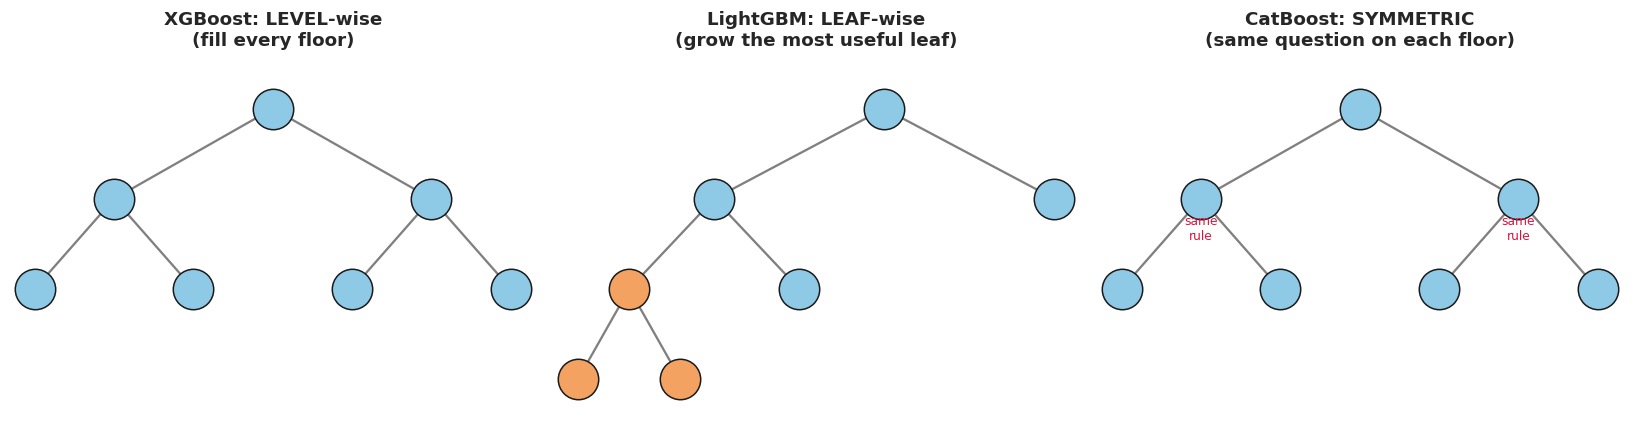

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
def draw(ax, nodes, edges, title, hl=()):
    for (a, b) in edges: ax.plot([nodes[a][0], nodes[b][0]], [nodes[a][1], nodes[b][1]], color='gray', lw=1.5, zorder=1)
    for k, (x, y) in nodes.items():
        ax.scatter(x, y, s=700, color='#f4a261' if k in hl else '#8ecae6', edgecolor='k', zorder=2)
    ax.set_title(title, fontsize=12, weight='bold'); ax.axis('off'); ax.set_ylim(-3.6, .6)
n1 = {0:(0,0),1:(-2,-1),2:(2,-1),3:(-3,-2),4:(-1,-2),5:(1,-2),6:(3,-2)}
e1 = [(0,1),(0,2),(1,3),(1,4),(2,5),(2,6)]
draw(axes[0], n1, e1, 'XGBoost: LEVEL-wise\n(fill every floor)')
n2 = {0:(0,0),1:(-2,-1),2:(2,-1),3:(-3,-2),4:(-1,-2),5:(-3.6,-3),6:(-2.4,-3)}
e2 = [(0,1),(0,2),(1,3),(1,4),(3,5),(3,6)]
draw(axes[1], n2, e2, 'LightGBM: LEAF-wise\n(grow the most useful leaf)', hl=(3,5,6))
draw(axes[2], n1, e1, 'CatBoost: SYMMETRIC\n(same question on each floor)')
for x in (-2, 2): axes[2].text(x, -1.45, 'same\nrule', ha='center', fontsize=8, color='crimson')
plt.tight_layout(); plt.show()

## 1.3 Scenario 1 — 🏦 *Will this customer default on a loan?*
A bank has 8,000+ past loan customers. For each one we know income, credit score, city, job, loan purpose... and whether they **defaulted** (didn't repay).
We want a model that flags risky applicants **before** giving the loan.

**Why boosting?** The data is *tabular* (rows & columns), has **mixed types** (numbers + categories), **missing values**, and **non-linear interactions**
("high loan + low credit score" is much worse than each alone). This is exactly where boosted trees beat everything else.

### Step 1 — Load & first look

In [3]:
loan = pd.read_csv(find_file('loan_default.csv'))
print(loan.shape)
loan.head()

(8120, 16)


,customer_id,age,city,occupation,loan_purpose,monthly_income,loan_amount,tenure_months,credit_score,existing_emi,num_late_payments,employment_years,has_cosigner,debt_to_income,recovery_agent_assigned,defaulted
0,CUST00606,46,Delhi,Salaried,Business,81400,487000.0,12,682.0,15800.0,2,12.0,0,0.693,0,0
1,CUST03393,64,Hyderabad,Salaried,Vehicle,47100,657000.0,120,730.0,8000.0,2,25.1,0,0.286,0,0
2,CUST07697,62,Delhi,Salaried,Personal,"₹33,200",780000.0,120,881.0,9400.0,0,15.1,0,0.479,0,0
3,CUST05811,53,Hyderabad,Business,Home,"₹20,000",139000.0,120,680.0,3800.0,1,21.3,0,0.248,0,0
4,CUST03651,27,hyderabad,Self-Employed,Education,"₹36,900",816000.0,120,NaN,6000.0,2,0.0,0,0.347,0,0


In [4]:
loan.info()

<class 'pandas.DataFrame'>
RangeIndex: 8120 entries, 0 to 8119
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              8120 non-null   str    
 1   age                      8120 non-null   int64  
 2   city                     8120 non-null   str    
 3   occupation               8120 non-null   str    
 4   loan_purpose             8120 non-null   str    
 5   monthly_income           8120 non-null   str    
 6   loan_amount              8120 non-null   float64
 7   tenure_months            8120 non-null   int64  
 8   credit_score             7662 non-null   float64
 9   existing_emi             8120 non-null   float64
 10  num_late_payments        8120 non-null   int64  
 11  employment_years         7792 non-null   float64
 12  has_cosigner             8120 non-null   int64  
 13  debt_to_income           8120 non-null   float64
 14  recovery_agent_assigned  8120 non-n

### 🕵️ Detective round 1 — find the problems
Run the cell below. **Before reading the hints, list every problem you can see** (there are 7).

Duplicate rows       : 120
Missing values:
 credit_score        458
employment_years    328
dtype: int64 

City values          : <StringArray>
[      'Delhi',   'Hyderabad',   'hyderabad',   'Bengaluru',        'Pune',
   'HYDERABAD',      'Mumbai',     'Chennai',     'chennai',      'mumbai',
       'DELHI',   'bengaluru', ' Bengaluru ',   ' Chennai ',    ' Mumbai ',
 ' Hyderabad ',       'delhi',   'BENGALURU',        'pune',     ' Delhi ',
     'CHENNAI',      'MUMBAI',        'PUNE',      ' Pune ']
Length: 24, dtype: str
monthly_income dtype : str -> ['81400', '47100', '₹33,200', '₹20,000']
Age min/max          : 0 199
Class balance (defaulted):
defaulted
0    0.902
1    0.098
Name: proportion, dtype: float64


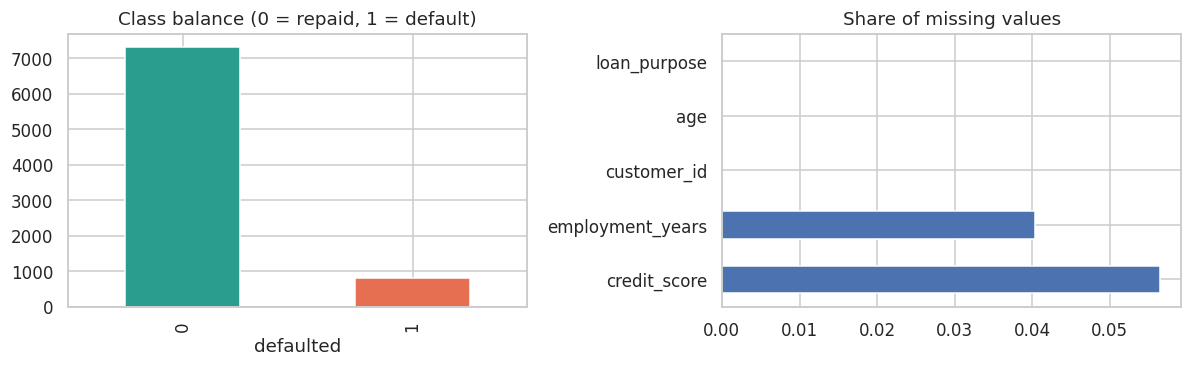

In [5]:
print('Duplicate rows       :', loan.duplicated().sum())
print('Missing values:\n', loan.isna().sum()[loan.isna().sum() > 0], '\n')
print('City values          :', loan['city'].unique())
print('monthly_income dtype :', loan['monthly_income'].dtype, '->', loan['monthly_income'].head(4).tolist())
print('Age min/max          :', loan['age'].min(), loan['age'].max())
print('Class balance (defaulted):'); print(loan['defaulted'].value_counts(normalize=True).round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
loan['defaulted'].value_counts().plot.bar(ax=ax[0], color=['#2a9d8f', '#e76f51'], title='Class balance (0 = repaid, 1 = default)')
loan.isna().mean().sort_values(ascending=False).head(5).plot.barh(ax=ax[1], title='Share of missing values')
plt.tight_layout(); plt.show()

<details><summary>💡 Hints (open only after trying)</summary>

1. **Duplicates** — the same customer appears twice. Duplicates leak between train/test and fake a better score.
2. `monthly_income` is **text** (`₹45,000`) — a model needs numbers. 
3. `city` has `hyderabad`, `HYDERABAD`, ` Hyderabad ` — the same city spelled many ways = many fake categories.
4. `credit_score` and `employment_years` have **missing** values. (Boosters can handle NaN, but we should understand what we're doing.)
5. `age` contains **0, 150, 199** — impossible values.
6. **Imbalance** — only ~10% default. Accuracy alone will lie to you (predicting "nobody defaults" gives 90%!). Use ROC-AUC / F1.
7. A column that looks *too good*: `recovery_agent_assigned`. Ask: **is this known at the time of giving the loan?** (Detective round 2.)
</details>

### ✅ Solution 1 — cleaning

In [6]:
df = loan.drop_duplicates().copy()                                           # 1 duplicates
df['monthly_income'] = (df['monthly_income'].astype(str).str.replace('[\u20b9,]', '', regex=True).astype(float))   # 2 text -> number
df['city'] = df['city'].str.strip().str.title()                              # 3 one spelling per city
df.loc[(df['age'] < 18) | (df['age'] > 80), 'age'] = np.nan                   # 5 impossible ages -> missing
df['age'] = df['age'].fillna(df['age'].median())
print(df.shape, '| cities:', sorted(df['city'].unique()))
print('Still missing:', df.isna().sum()[df.isna().sum() > 0].to_dict(), '(left as NaN on purpose - boosters learn what to do with NaN)')

(8000, 16) | cities: ['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Mumbai', 'Pune']
Still missing: {'credit_score': 453, 'employment_years': 324} (left as NaN on purpose - boosters learn what to do with NaN)


### 🕵️ Detective round 2 — the "too good to be true" feature (data leakage)
**Analogy:** a student who sees the answer key during the exam. Score 100% — but learned nothing.

recovery_agent_assigned
0    0.003
1    0.836
Name: defaulted, dtype: float64


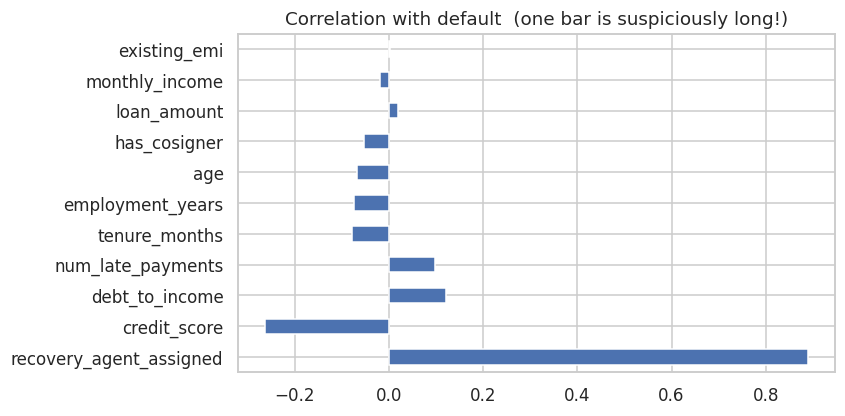

In [7]:
print(df.groupby('recovery_agent_assigned')['defaulted'].mean().round(3))
num_corr = df.select_dtypes('number').corr()['defaulted'].drop('defaulted').sort_values(key=abs, ascending=False)
num_corr.plot.barh(title='Correlation with default  (one bar is suspiciously long!)', figsize=(7, 4)); plt.show()

<details><summary>💡 Hint</summary>
A recovery agent is assigned <b>after</b> a customer stops paying. At loan-approval time this column does not exist → it is <b>leakage</b>.
A model using it would shine in the notebook and fail in real life. <b>Drop it.</b> (Also drop <code>customer_id</code> — it is just a label.)
</details>

In [8]:
df = df.drop(columns=['recovery_agent_assigned', 'customer_id'])
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
age,8000.0,43.0,12.9,21.0,32.0,43.0,54.0,65.0
monthly_income,8000.0,45406.3,24559.3,4800.0,28500.0,40000.0,55900.0,309900.0
loan_amount,8000.0,750649.2,568363.8,34000.0,346000.0,611000.0,985000.0,5245000.0
tenure_months,8000.0,54.3,34.2,12.0,24.0,48.0,84.0,120.0
credit_score,7547.0,687.6,83.8,358.0,632.0,688.0,743.0,900.0
existing_emi,8000.0,10304.0,8831.3,0.0,4075.0,8200.0,14000.0,137400.0
num_late_payments,8000.0,1.2,1.1,0.0,0.0,1.0,2.0,7.0
employment_years,7676.0,12.2,9.4,0.0,4.4,10.7,18.4,42.5
has_cosigner,8000.0,0.3,0.4,0.0,0.0,0.0,1.0,1.0
debt_to_income,8000.0,0.7,0.5,0.0,0.4,0.6,0.9,2.9


### Step 2 — Visual EDA: what drives default?

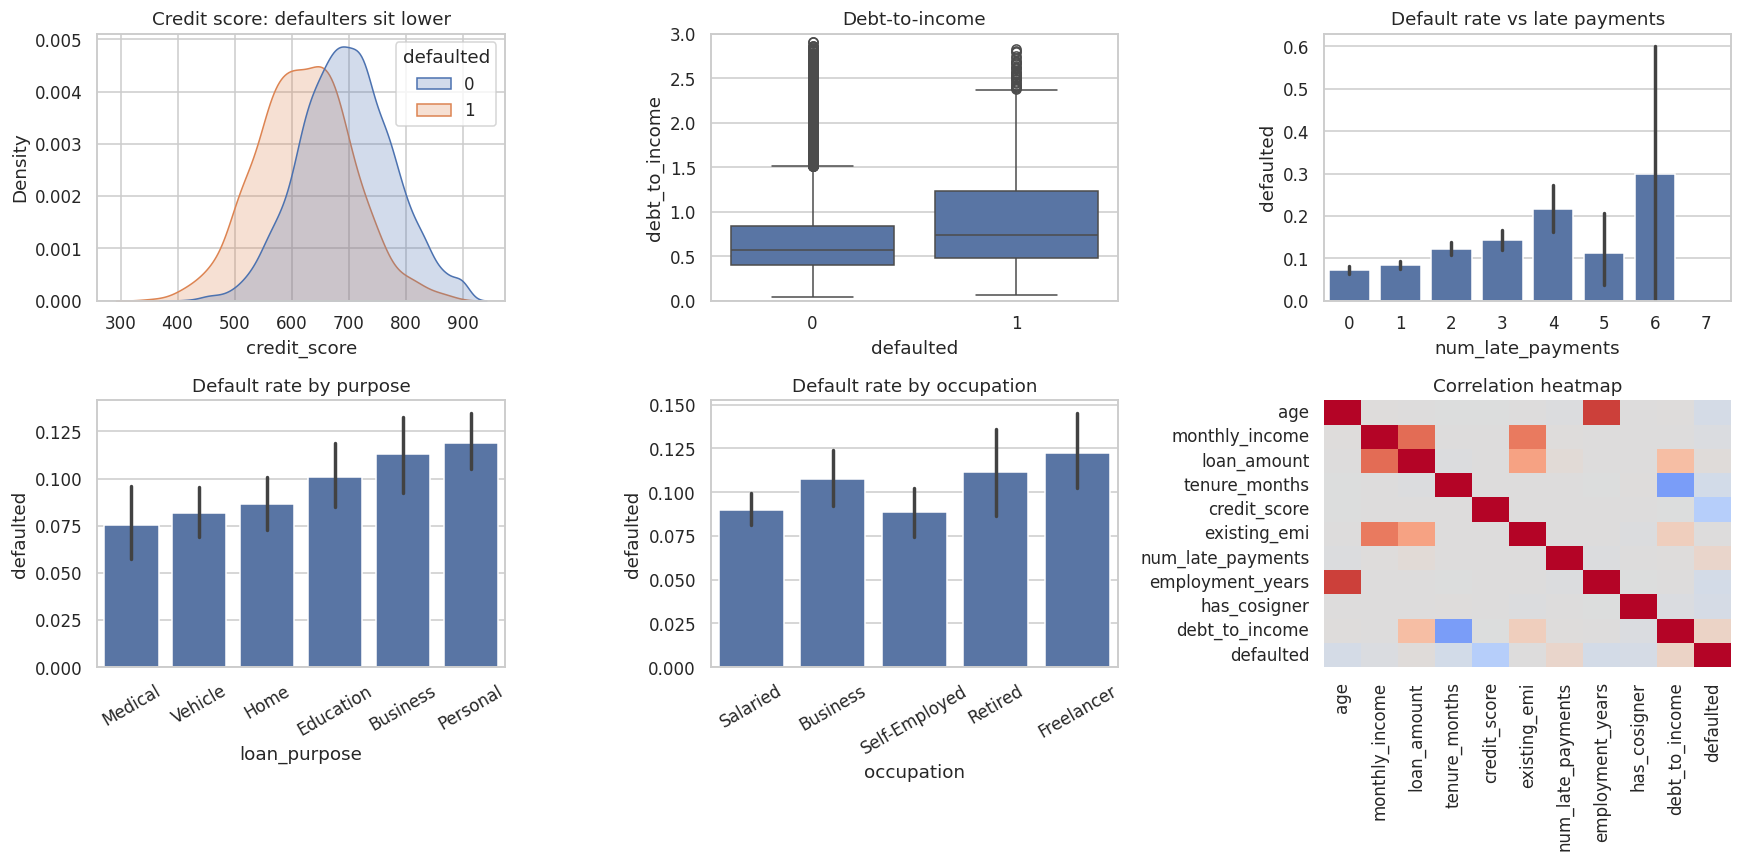

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
sns.kdeplot(data=df, x='credit_score', hue='defaulted', common_norm=False, fill=True, ax=ax[0,0]); ax[0,0].set_title('Credit score: defaulters sit lower')
sns.boxplot(data=df, x='defaulted', y='debt_to_income', ax=ax[0,1]); ax[0,1].set_ylim(0, 3); ax[0,1].set_title('Debt-to-income')
sns.barplot(data=df, x='num_late_payments', y='defaulted', ax=ax[0,2]); ax[0,2].set_title('Default rate vs late payments')
sns.barplot(data=df, x='loan_purpose', y='defaulted', ax=ax[1,0], order=df.groupby('loan_purpose')['defaulted'].mean().sort_values().index); ax[1,0].tick_params(axis='x', rotation=30); ax[1,0].set_title('Default rate by purpose')
sns.barplot(data=df, x='occupation', y='defaulted', ax=ax[1,1]); ax[1,1].tick_params(axis='x', rotation=30); ax[1,1].set_title('Default rate by occupation')
sns.heatmap(df.select_dtypes('number').corr(), cmap='coolwarm', center=0, ax=ax[1,2], cbar=False); ax[1,2].set_title('Correlation heatmap')
plt.tight_layout(); plt.show()

### Step 3 — Prepare data for the three models
- **XGBoost & LightGBM** accept pandas `category` columns (they split on category groups) — no one-hot needed.
- **CatBoost** takes the raw category *strings* and does its own smart encoding.
- Split **stratified** so train and test keep the same 10% default ratio.

In [10]:
target = 'defaulted'
cat_cols = ['city', 'occupation', 'loan_purpose']
X, y = df.drop(columns=target), df[target]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

def as_category(d):
    d = d.copy()
    for c in cat_cols: d[c] = d[c].astype('category')
    return d
Xc_tr, Xc_te = as_category(X_tr), as_category(X_te)
# make sure test categories use the same dictionary as train
for c in cat_cols: Xc_te[c] = pd.Categorical(Xc_te[c], categories=Xc_tr[c].cat.categories)
print(X_tr.shape, X_te.shape, '| default rate train/test:', y_tr.mean().round(3), y_te.mean().round(3))

(6400, 13) (1600, 13) | default rate train/test: 0.098 0.098


### Step 4 — Key hyper-parameters (the "knobs")

| Idea (analogy) | XGBoost | LightGBM | CatBoost |
|---|---|---|---|
| **Number of tutors** | `n_estimators` | `n_estimators` | `iterations` |
| **Step size** — how much each tutor is trusted (small = careful, needs more tutors) | `learning_rate` | `learning_rate` | `learning_rate` |
| **How complex each tutor's brain is** | `max_depth` | `num_leaves` (+`max_depth`) | `depth` |
| **Show each tutor only part of the class** (reduces over-fitting) | `subsample` | `subsample` (`bagging_fraction`) | `subsample` |
| **Show each tutor only some chapters (features)** | `colsample_bytree` | `colsample_bytree` | `rsm` |
| **Penalty for complicated answers** | `reg_lambda`, `reg_alpha`, `gamma` | `reg_lambda`, `min_gain_to_split` | `l2_leaf_reg` |
| **Minimum evidence needed for a rule** | `min_child_weight` | `min_child_samples` | `min_data_in_leaf` |
| **Imbalanced classes** | `scale_pos_weight` | `scale_pos_weight` / `is_unbalance` | `auto_class_weights` |

**Golden rule:** lower `learning_rate` + more trees + early stopping = best accuracy.

### Step 5 — Train all three and race them 🏁

In [11]:
imb = (y_tr == 0).sum() / (y_tr == 1).sum()        # ~9 : tells models that defaults are rare but important
models = {
 'XGBoost':  xgb.XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                               reg_lambda=1.0, scale_pos_weight=imb, enable_categorical=True, tree_method='hist',
                               eval_metric='auc', random_state=42, n_jobs=-1),
 'LightGBM': lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=15, subsample=0.8, subsample_freq=1,
                                colsample_bytree=0.8, scale_pos_weight=imb, random_state=42, verbose=-1, n_jobs=-1),
 'CatBoost': CatBoostClassifier(iterations=400, learning_rate=0.05, depth=4, auto_class_weights='Balanced',
                                cat_features=cat_cols, random_seed=42, verbose=0),
}
rows, probs = [], {}
for name, m in models.items():
    Xa, Xb = (X_tr.astype({c: str for c in cat_cols}).fillna({c: 'Unknown' for c in cat_cols}), X_te.astype({c: str for c in cat_cols})) if name == 'CatBoost' else (Xc_tr, Xc_te)
    t0 = time.time(); m.fit(Xa, y_tr); tt = time.time() - t0
    p = m.predict_proba(Xb)[:, 1]; probs[name] = p
    pred = (p > 0.5).astype(int)
    rows.append(dict(model=name, accuracy=accuracy_score(y_te, pred), f1=f1_score(y_te, pred), roc_auc=roc_auc_score(y_te, p), train_sec=tt))
res = pd.DataFrame(rows).set_index('model').round(3)
res

,accuracy,f1,roc_auc,train_sec
model,,,,
XGBoost,0.802,0.309,0.743,0.403
LightGBM,0.826,0.337,0.746,0.282
CatBoost,0.749,0.331,0.777,2.168


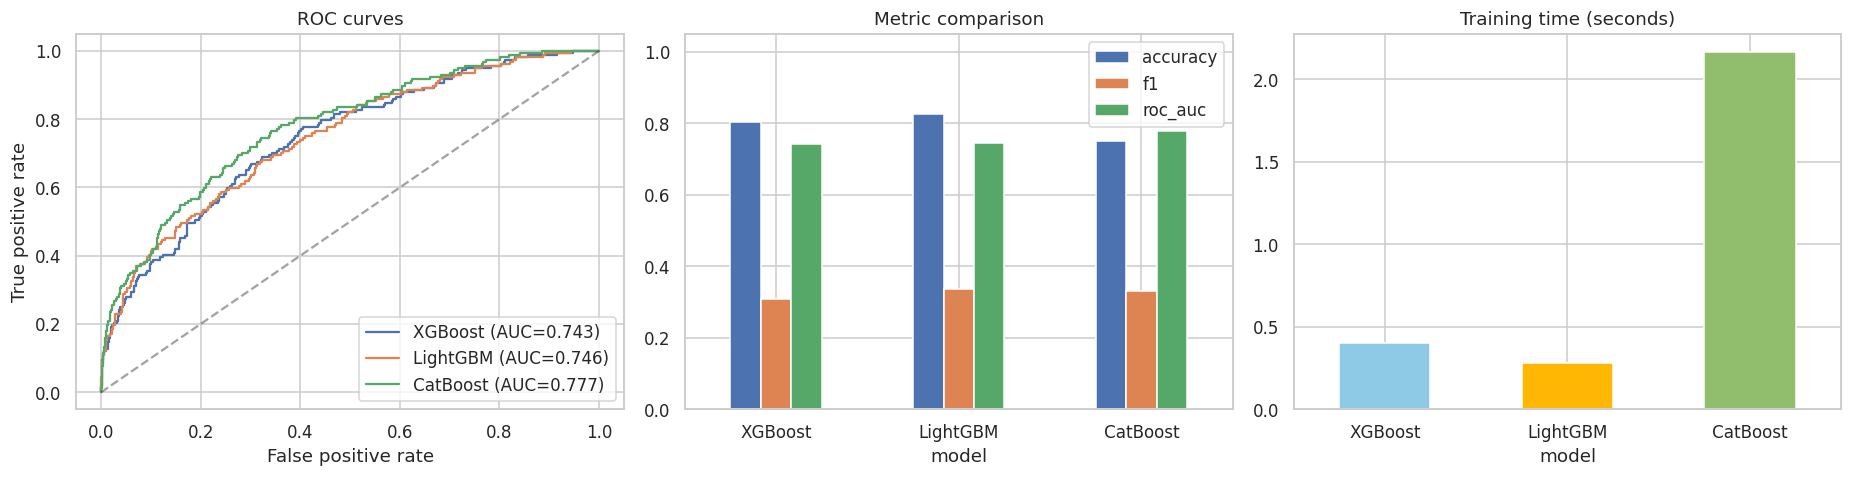

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_te, p); ax[0].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_te, p):.3f})')
ax[0].plot([0, 1], [0, 1], 'k--', alpha=.4); ax[0].set_title('ROC curves'); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate'); ax[0].legend()
res[['accuracy', 'f1', 'roc_auc']].plot.bar(ax=ax[1], rot=0); ax[1].set_title('Metric comparison'); ax[1].set_ylim(0, 1.05)
res['train_sec'].plot.bar(ax=ax[2], rot=0, color=['#8ecae6', '#ffb703', '#90be6d']); ax[2].set_title('Training time (seconds)')
plt.tight_layout(); plt.show()

**How to read it:** the closer the ROC curve hugs the top-left, the better. With 10% defaults, **accuracy is misleading** — look at **ROC-AUC** (ranking quality)
and **F1** (balance of catching defaulters vs. false alarms). On small data like this the three are close; the *time* column shows why LightGBM is loved on big data.

### Step 6 — Confusion matrices & feature importance (the *why* behind the prediction)

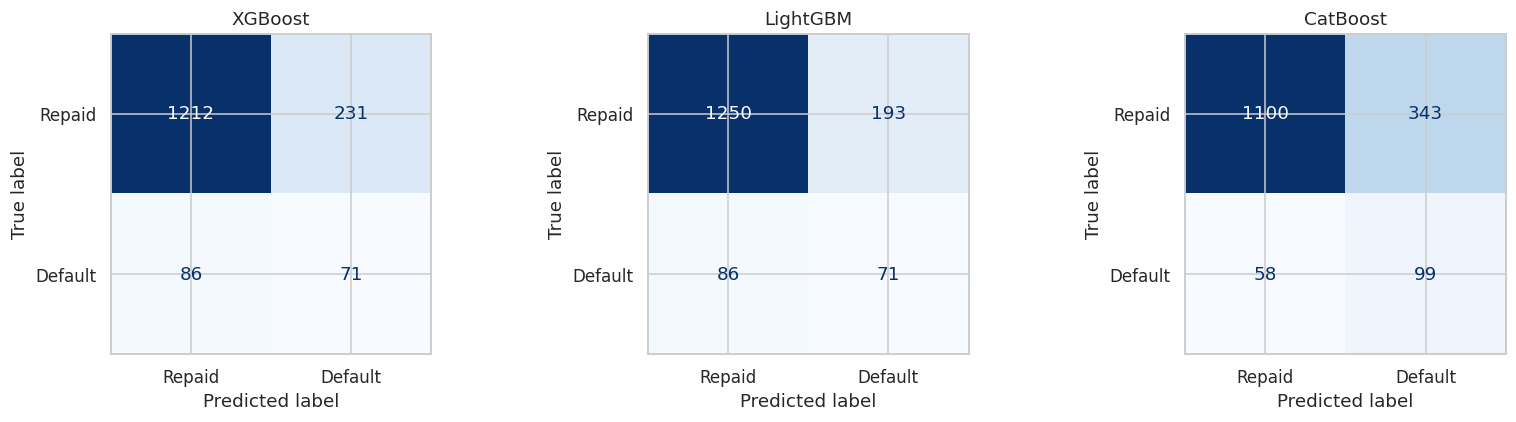

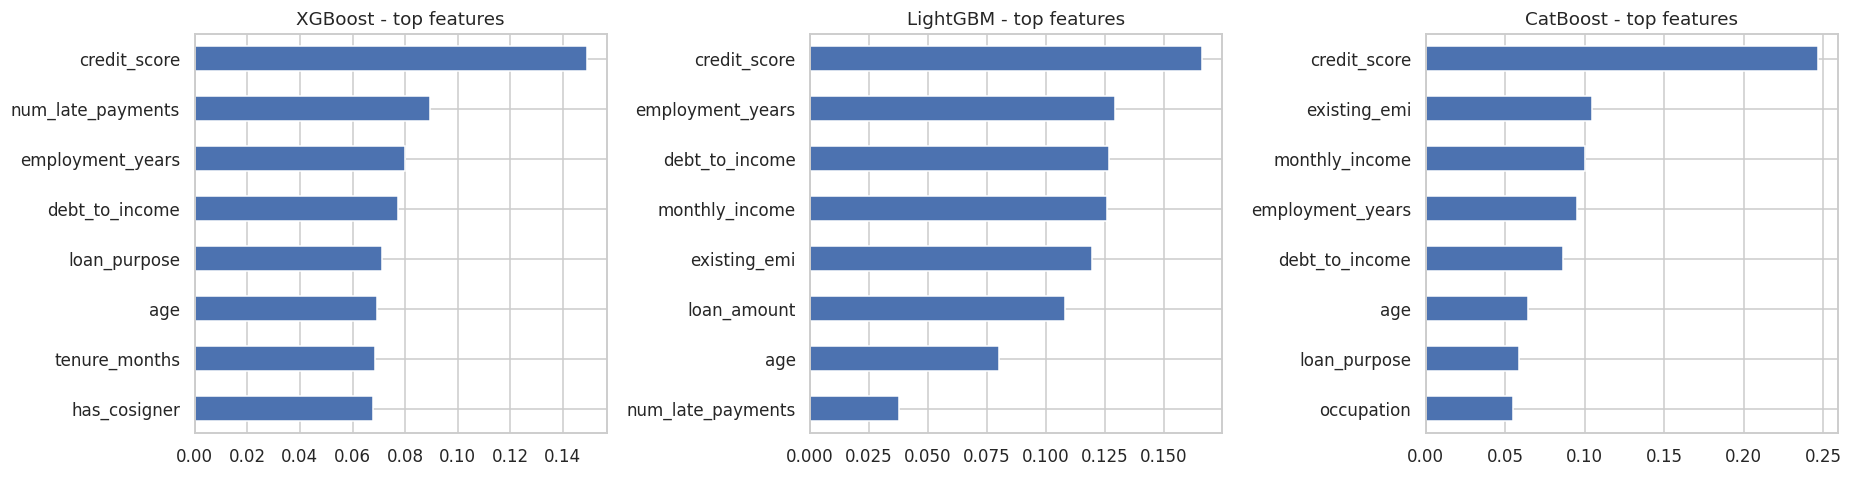

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (name, p) in zip(ax, probs.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_te, (p > .5).astype(int)), display_labels=['Repaid', 'Default']).plot(ax=a, colorbar=False, cmap='Blues')
    a.set_title(name)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
imp = {'XGBoost': models['XGBoost'].feature_importances_, 'LightGBM': models['LightGBM'].feature_importances_ / models['LightGBM'].feature_importances_.sum(),
       'CatBoost': models['CatBoost'].feature_importances_ / 100}
for a, (name, v) in zip(ax, imp.items()):
    pd.Series(v, index=X_tr.columns).sort_values().tail(8).plot.barh(ax=a, title=f'{name} - top features'); 
plt.tight_layout(); plt.show()

**Business reading:** the strongest drivers should be *credit score, late payments, debt-to-income* — exactly what a human credit officer looks at.
If a feature like `customer_id` or the leaky column topped this chart, that would be a red flag.

### Step 7 — Seeing the knobs in action (learning rate & depth)
**Analogy:** *learning rate* = how big a step the student takes when correcting a mistake. Tiny steps need many lessons; giant steps overshoot.

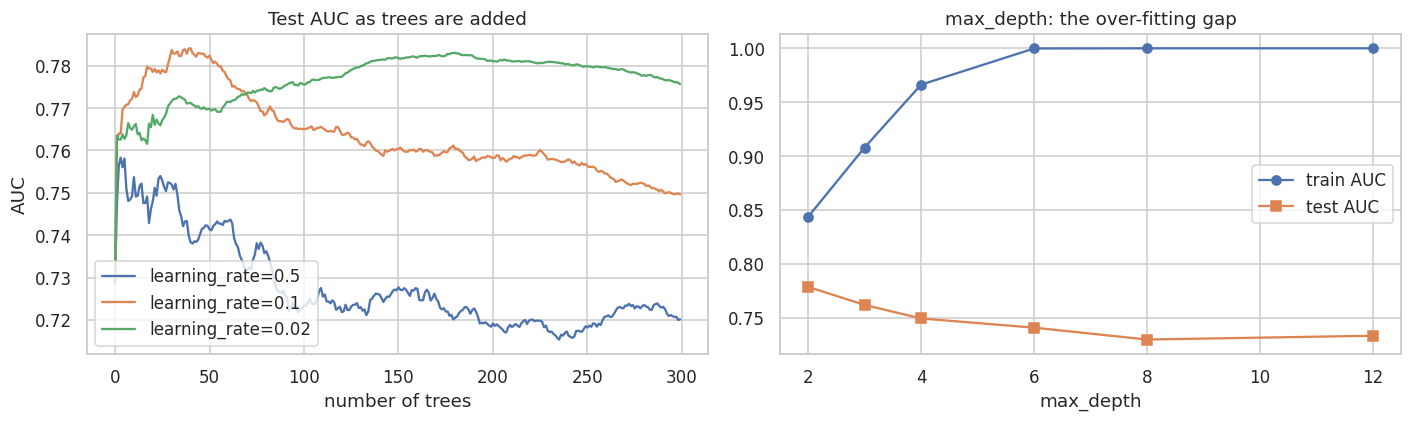

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for lr in [0.5, 0.1, 0.02]:
    m = lgb.LGBMClassifier(n_estimators=300, learning_rate=lr, num_leaves=15, verbose=-1, random_state=1)
    m.fit(Xc_tr, y_tr, eval_set=[(Xc_te, y_te)], eval_metric='auc')
    ax[0].plot(m.evals_result_['valid_0']['auc'], label=f'learning_rate={lr}')
ax[0].set_title('Test AUC as trees are added'); ax[0].set_xlabel('number of trees'); ax[0].set_ylabel('AUC'); ax[0].legend()
depths = [2, 3, 4, 6, 8, 12]; tr_s, te_s = [], []
for d in depths:
    m = xgb.XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=d, enable_categorical=True, tree_method='hist', random_state=1)
    m.fit(Xc_tr, y_tr); tr_s.append(roc_auc_score(y_tr, m.predict_proba(Xc_tr)[:, 1])); te_s.append(roc_auc_score(y_te, m.predict_proba(Xc_te)[:, 1]))
ax[1].plot(depths, tr_s, 'o-', label='train AUC'); ax[1].plot(depths, te_s, 's-', label='test AUC'); ax[1].set_title('max_depth: the over-fitting gap'); ax[1].set_xlabel('max_depth'); ax[1].legend()
plt.tight_layout(); plt.show()

**Observation:** a high learning rate rises fast but wobbles/overfits; a low one is smooth and slow. As depth grows, **train AUC → 1.0 while test AUC stalls or drops**
— the gap is over-fitting (a student who memorised the practice paper).
Fix it with: smaller depth, `subsample`, `colsample_bytree`, regularisation, and **early stopping**.

### Step 8 — Early stopping (let the model decide how many tutors it needs)

In [15]:
m = xgb.XGBClassifier(n_estimators=2000, learning_rate=0.03, max_depth=4, subsample=.8, colsample_bytree=.8, enable_categorical=True,
                      tree_method='hist', eval_metric='auc', early_stopping_rounds=50, random_state=42)
m.fit(Xc_tr, y_tr, eval_set=[(Xc_te, y_te)], verbose=False)
print('Best number of trees:', m.best_iteration, '| AUC:', round(roc_auc_score(y_te, m.predict_proba(Xc_te)[:, 1]), 4))

Best number of trees: 104 | AUC: 0.7848


*(Strictly, early stopping should use a separate validation split, not the test set — that's an advanced practice task below.)*

# PART 2 — Boosters for **Regression** ⚡
## Scenario 2 — 🔌 *How much electricity will the city need?*
A power company must decide how many MW to generate **tomorrow**. Too little → blackouts, too much → wasted money.
Inputs: temperature, humidity, hour of day, weekday, holiday, zone type, industrial activity. Target: `demand_mw` (a **number**, so it's *regression*).

**Why boosters?** Demand has a *U-shape* vs temperature (heaters in cold, AC in heat), peaks at certain hours, and interacts with zone type.
A straight line can't capture this; trees + boosting can.

Same three libraries, but the "loss" is now squared error (RMSE) instead of log-loss.

In [16]:
el = pd.read_csv(find_file('electricity_demand.csv'))
print(el.shape); el.head()

(7000, 8)


,temperature_c,humidity_pct,hour,day_of_week,is_holiday,zone,industrial_index,demand_mw
0,39.2,84.4,7,3,0,Residential,0.23,280.9
1,21.5,38.2,1,4,0,Residential,0.46,237.2
2,41.6,30.6,0,6,0,Residential,0.42,280.3
3,37.8,89.1,16,3,0,Residential,0.16,289.8
4,40.8,79.3,7,4,0,Industrial,0.59,487.6


### 🕵️ Detective round 3 — electricity data

zone
Residential    2314
Mixed          1693
Commercial     1682
Industrial     1005
Resedential     104
MIXED            88
commercial       65
Industrail       49
Name: count, dtype: int64 

count    7000.0
mean      328.4
std       406.3
min         0.0
25%       266.7
50%       298.8
75%       345.1
max      9999.0
Name: demand_mw, dtype: float64 

Missing: {'humidity_pct': 332}


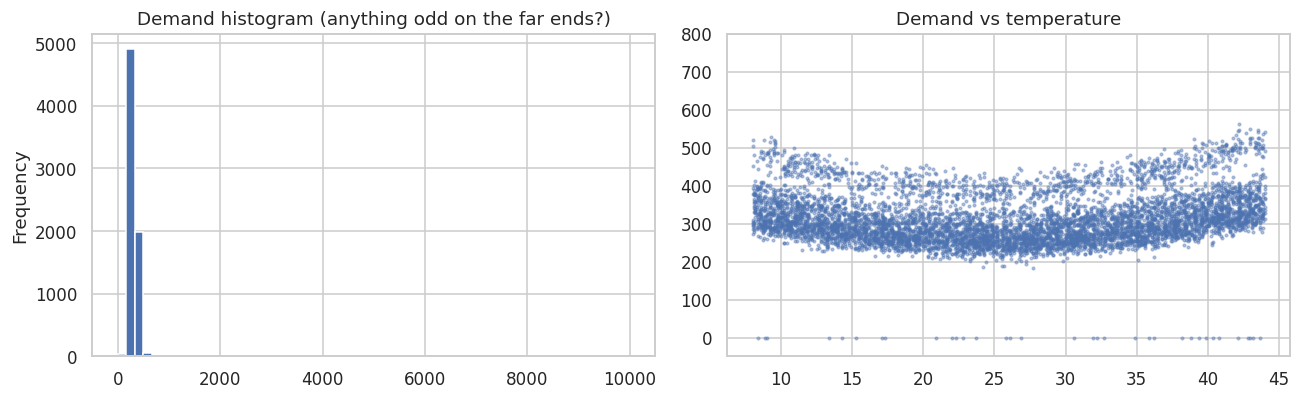

In [17]:
print(el['zone'].value_counts(), '\n')
print(el['demand_mw'].describe().round(1), '\n')
print('Missing:', el.isna().sum()[el.isna().sum() > 0].to_dict())
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
el['demand_mw'].plot.hist(bins=60, ax=ax[0], title='Demand histogram (anything odd on the far ends?)')
ax[1].scatter(el['temperature_c'], el['demand_mw'], s=3, alpha=.4); ax[1].set_ylim(-50, 800); ax[1].set_title('Demand vs temperature'); plt.tight_layout(); plt.show()

<details><summary>💡 Hints</summary>

- `zone` has typos: *Resedential, Industrail, commercial, MIXED* → unify spelling.
- `demand_mw` has **0** (power outage — real demand wasn't measured) and **9999** (sensor error) → physically impossible for normal operation; remove them (or treat as missing).
- `humidity_pct` has missing values → boosters accept NaN, but for **SVR later** we must fill them.
- Notice the **U-shape**: this is why linear regression fails here.
</details>

In [18]:
el['zone'] = el['zone'].str.strip().str.lower().replace({'resedential': 'residential', 'industrail': 'industrial'}).str.title()
el = el[(el['demand_mw'] > 50) & (el['demand_mw'] < 2000)].reset_index(drop=True)
print(el.shape, el['zone'].unique())

(6954, 8) <StringArray>
['Residential', 'Industrial', 'Mixed', 'Commercial']
Length: 4, dtype: str


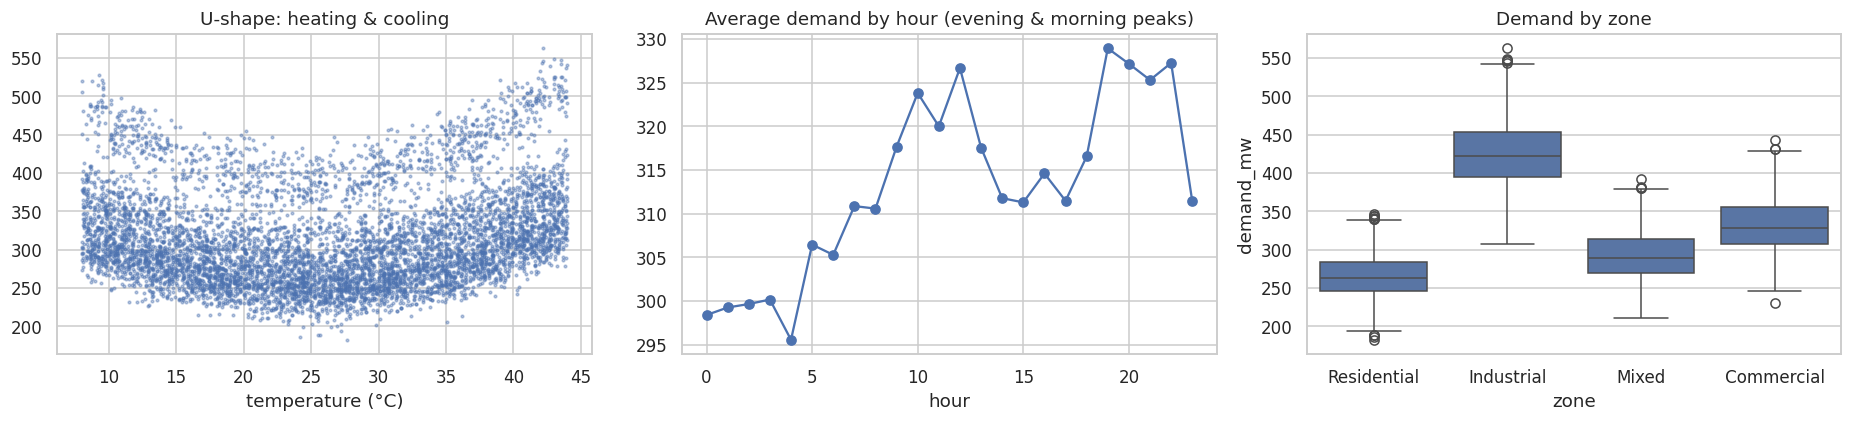

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].scatter(el['temperature_c'], el['demand_mw'], s=3, alpha=.4); ax[0].set_title('U-shape: heating & cooling'); ax[0].set_xlabel('temperature (°C)')
el.groupby('hour')['demand_mw'].mean().plot(ax=ax[1], marker='o', title='Average demand by hour (evening & morning peaks)')
sns.boxplot(data=el, x='zone', y='demand_mw', ax=ax[2]); ax[2].set_title('Demand by zone')
plt.tight_layout(); plt.show()

In [20]:
Xr, yr = el.drop(columns='demand_mw'), el['demand_mw']
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=42)
rcat = ['zone']
def cat_df(d, ref=None):
    d = d.copy(); d['zone'] = pd.Categorical(d['zone'], categories=ref if ref is not None else sorted(el['zone'].unique())); return d
reg = {
 'XGBoost':  xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=5, subsample=.8, colsample_bytree=.8, enable_categorical=True, tree_method='hist', random_state=42),
 'LightGBM': lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=31, subsample=.8, subsample_freq=1, colsample_bytree=.8, verbose=-1, random_state=42),
 'CatBoost': CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6, cat_features=rcat, random_seed=42, verbose=0),
}
rrows, rpred = [], {}
for name, m in reg.items():
    A, B = (Xr_tr.fillna({'zone': 'Unknown'}), Xr_te) if name == 'CatBoost' else (cat_df(Xr_tr), cat_df(Xr_te))
    t0 = time.time(); m.fit(A, yr_tr); tt = time.time() - t0
    p = m.predict(B); rpred[name] = p
    rrows.append(dict(model=name, RMSE=mean_squared_error(yr_te, p) ** .5, MAE=mean_absolute_error(yr_te, p), R2=r2_score(yr_te, p), train_sec=tt))
rres = pd.DataFrame(rrows).set_index('model').round(3); rres

,RMSE,MAE,R2,train_sec
model,,,,
XGBoost,6.618,5.232,0.989,0.370
LightGBM,6.929,5.509,0.988,0.337
CatBoost,6.343,5.014,0.990,1.061


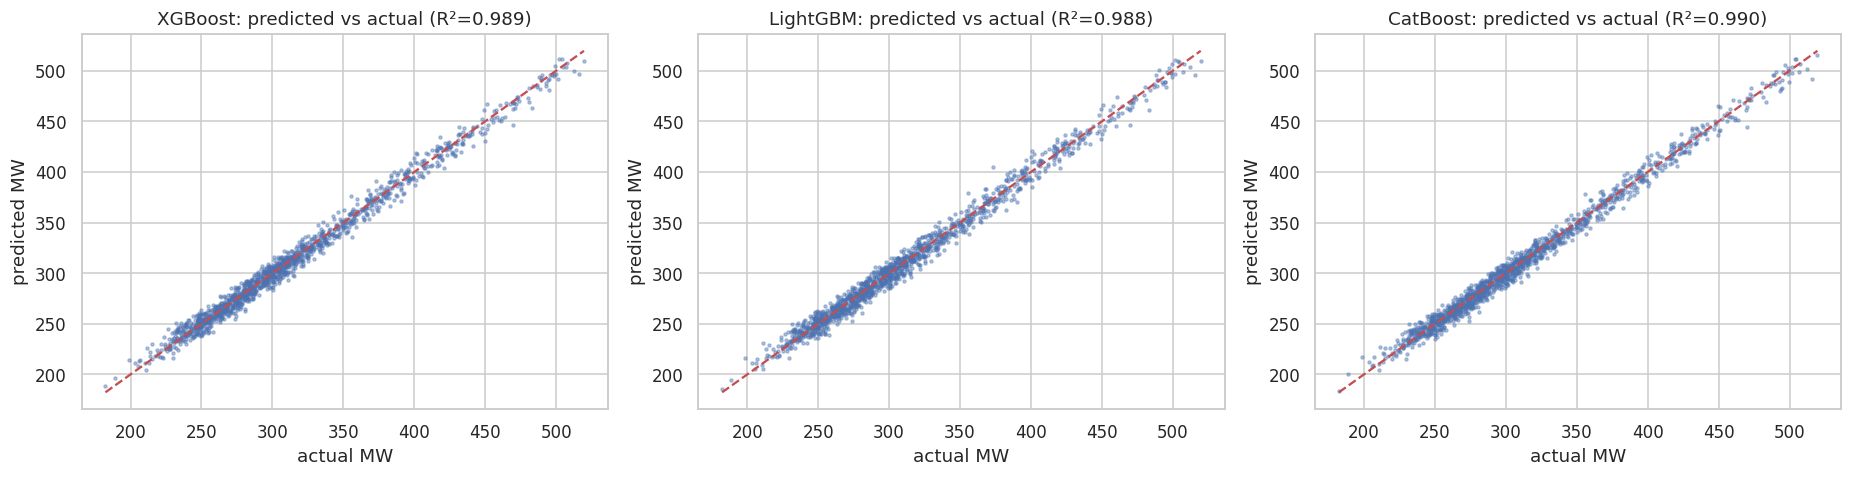

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, (name, p) in zip(ax, rpred.items()):
    a.scatter(yr_te, p, s=4, alpha=.4); lim = [yr_te.min(), yr_te.max()]; a.plot(lim, lim, 'r--'); a.set_title(f'{name}: predicted vs actual (R²={r2_score(yr_te, p):.3f})'); a.set_xlabel('actual MW'); a.set_ylabel('predicted MW')
plt.tight_layout(); plt.show()

**Reading metrics (regression):**
- **RMSE** — typical error in MW, punishes big misses harder. **MAE** — average absolute error (easy to explain to a manager).
- **R²** — share of the ups-and-downs in demand the model explains (1.0 = perfect).

Points hugging the red diagonal = good predictions.

## 1.4 🧭 Which booster when?

| Situation | Pick | Why |
|---|---|---|
| Lots of categorical columns (city, product, job) and you hate preprocessing | **CatBoost** | Native categorical handling, strong defaults |
| Millions of rows / need speed / limited RAM | **LightGBM** | Histogram + leaf-wise growth = fastest |
| Medium data, need reliability, many tutorials & integrations, strong regularisation | **XGBoost** | Mature, stable, well-documented |
| Small data (<5k rows), over-fitting worry | **CatBoost** or shallow **XGBoost** | Symmetric trees / regularisation |
| Need GPU training | All three support it; LightGBM & CatBoost GPU are easy | |
| Competition: final score matters | **Blend all three** | Different errors cancel out |

# PART 3 — Support Vector Machines (SVM) 🛣️

## 3.1 The idea in one picture
**Analogy — the road between two villages.** Village A (blue houses) and village B (red houses). You must build a road separating them.
There are many possible roads, but the **safest road is the widest one** — as far as possible from both villages.
The houses *right at the edge of the road* are the **support vectors**: they alone decide where the road goes. Move any faraway house and nothing changes!

- **SVC** = Support Vector *Classifier* (separate classes)  
- **SVR** = Support Vector *Regressor* (fit a curve with an "allowed error tube")

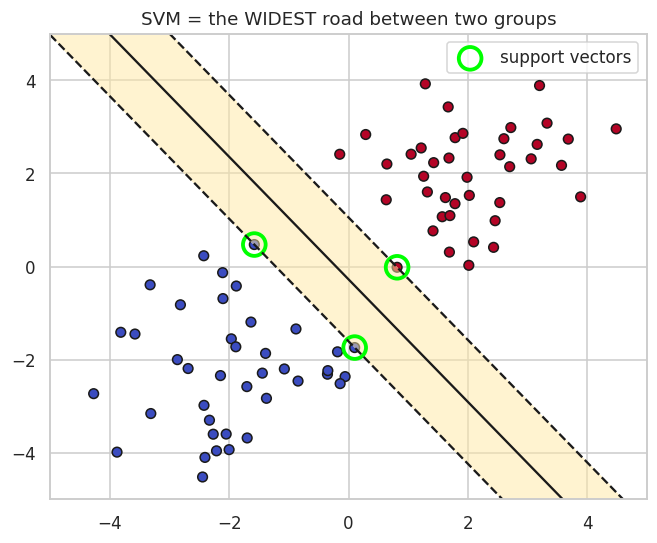

Only 3 of 80 points matter (the support vectors).


In [22]:
from sklearn.datasets import make_blobs
Xb, yb = make_blobs(n_samples=80, centers=[(-2, -2), (2, 2)], cluster_std=1.1, random_state=7)
clf = SVC(kernel='linear', C=1000).fit(Xb, yb)
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(Xb[:, 0], Xb[:, 1], c=yb, cmap='coolwarm', s=40, edgecolor='k')
xx, yy = np.meshgrid(np.linspace(-5, 5, 200), np.linspace(-5, 5, 200))
Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors='k', linestyles=['--', '-', '--'])
ax.contourf(xx, yy, Z, levels=[-1, 1], colors=['#ffe8a3'], alpha=.5)
ax.scatter(*clf.support_vectors_.T, s=220, facecolors='none', edgecolors='lime', linewidths=2.5, label='support vectors')
ax.set_title('SVM = the WIDEST road between two groups'); ax.legend(); plt.show()
print('Only', len(clf.support_vectors_), 'of', len(Xb), 'points matter (the support vectors).')

## 3.2 The three big ideas

1. **Margin** — the width of the road. SVM maximises it → better generalisation to new houses.
2. **Soft margin & `C`** — real life is messy: a few houses are *on the road*. 
   - **Large C** = strict police: "no house on the road!" → narrow road, may over-fit.  
   - **Small C** = relaxed: tolerate a few violations → wider road, smoother.
3. **Kernel trick** — what if the villages are **not separable by a straight road** (one village is *inside* a ring of the other)?

### 3.3 The kernel trick 🎩
**Analogy:** red and blue coins lie on a table: blue in the middle, red around them. No straight line separates them.
**Throw the coins into the air** — heavier (outer) coins fly higher. Now a flat sheet of paper slides between them in 3-D!
The kernel computes this "lifted" geometry **without actually building the extra dimension** (that's the *trick* — it's cheap).

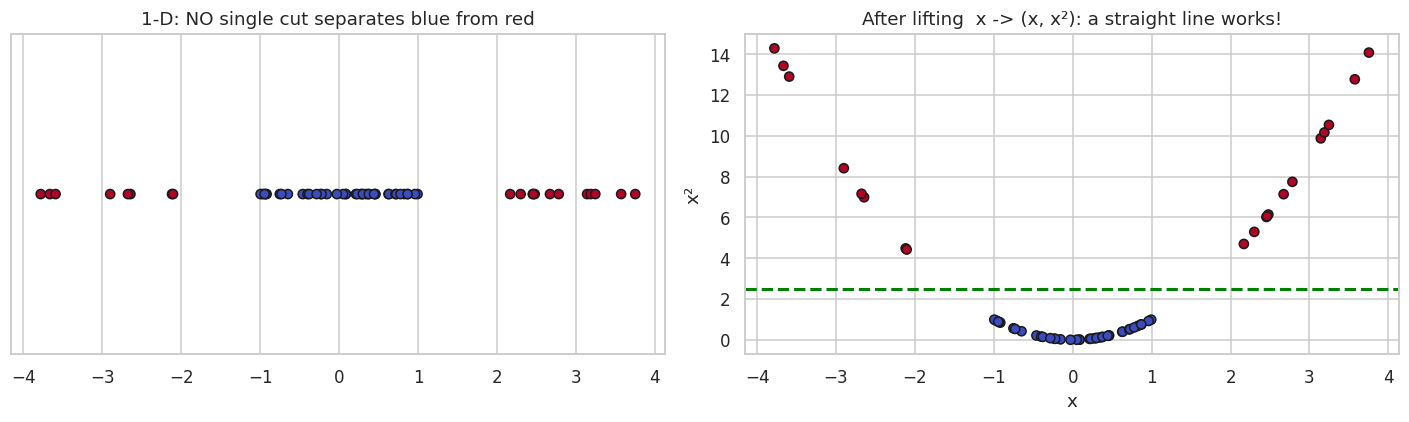

In [23]:
rng = np.random.default_rng(0)
x1 = np.concatenate([rng.uniform(-1, 1, 40), rng.uniform(2, 4, 20) * rng.choice([-1, 1], 20)])
lab = np.r_[np.zeros(40), np.ones(20)]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].scatter(x1, np.zeros_like(x1), c=lab, cmap='coolwarm', edgecolor='k'); ax[0].set_title('1-D: NO single cut separates blue from red'); ax[0].set_yticks([])
ax[1].scatter(x1, x1 ** 2, c=lab, cmap='coolwarm', edgecolor='k'); ax[1].axhline(2.5, color='green', ls='--', lw=2)
ax[1].set_title('After lifting  x -> (x, x²): a straight line works!'); ax[1].set_xlabel('x'); ax[1].set_ylabel('x²')
plt.tight_layout(); plt.show()

| Kernel | Everyday picture | Use when |
|---|---|---|
| **Linear** | A straight road | Data is (almost) linearly separable; many features (text); need speed/interpretability |
| **Polynomial** (`degree`) | A gently curved road | Smooth curved boundaries, interactions between features |
| **RBF (Gaussian)** | A flexible rubber band around groups | **Default choice** when you don't know the shape |
| Sigmoid | Neural-net-like | Rarely used |

**`gamma` (RBF/poly) — the reach of each point:** think of every house as a **lamp**. *High gamma* = tiny bright circle (very local, wiggly boundary, over-fit).
*Low gamma* = big soft glow (smooth, may under-fit).

### 3.4 Scenario 3 — 🌾 *Is the crop stressed?*
A smart farm has sensors: soil moisture, air temperature, soil pH, nitrogen, sunlight. A crop thrives only inside a **comfort zone**:
not too dry/wet **and** not too hot/cold. Outside that zone → stressed. This healthy zone is a **blob/ellipse**, so a straight line fails but an **RBF-SVM** thrives.

**Why SVM here?** moderate data size (~6k), few numeric features, a *curvy* boundary, and we want a clean, mathematically neat separator.

In [24]:
farm = pd.read_csv(find_file('soil_crop_stress.csv')); print(farm.shape); farm.head()

(6080, 6)


,soil_moisture_pct,air_temp_c,soil_ph,nitrogen_ppm,sunlight_hours,crop_status
0,29.5,19.1,6.50,156.0,4.3,Stressed
1,50.5,20.3,5.20,174.0,3.7,Stressed
2,15.0,19.3,6.57,297.0,8.6,Healthy
3,33.3,33.1,7.00,172.0,6.3,Healthy
4,34.5,26.6,6.60,280.0,9.4,Healthy


### 🕵️ Detective round 4 — sensors lie sometimes

Duplicates: 80
                     min    max   mean
soil_moisture_pct -999.0   60.0   28.4
air_temp_c          14.0  107.1   30.5
soil_ph              4.4    9.0    6.6
nitrogen_ppm        20.0  300.0  158.0
sunlight_hours       3.0   12.0    7.5
Missing: {'soil_ph': 277}


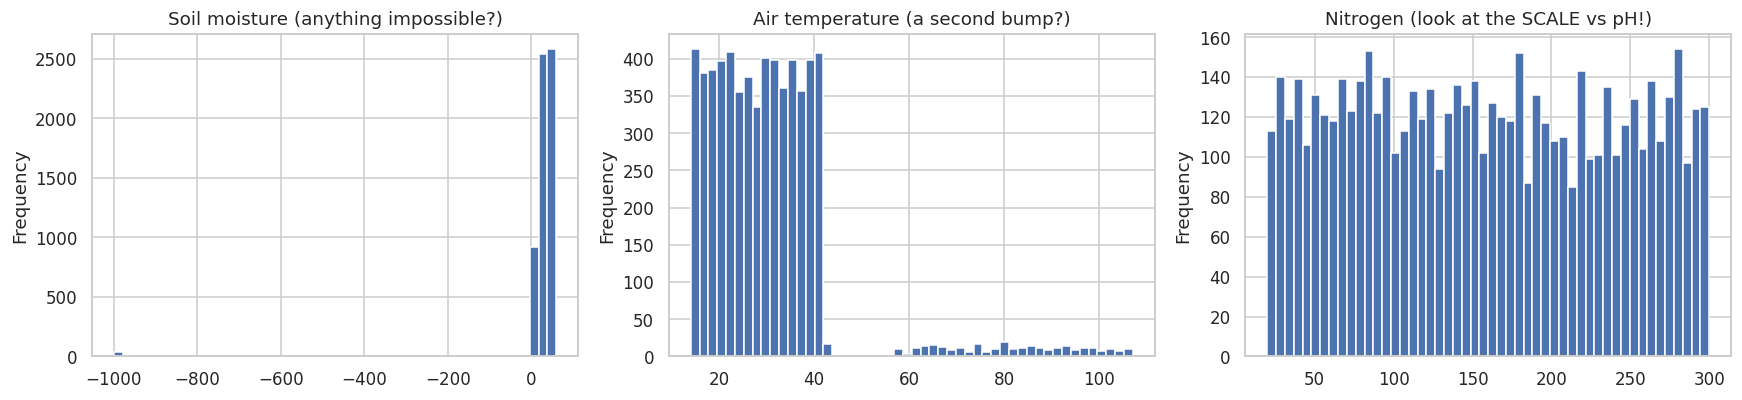

In [25]:
print('Duplicates:', farm.duplicated().sum())
print(farm.describe().T[['min', 'max', 'mean']].round(1))
print('Missing:', farm.isna().sum()[farm.isna().sum() > 0].to_dict())
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
farm['soil_moisture_pct'].plot.hist(bins=50, ax=ax[0], title='Soil moisture (anything impossible?)')
farm['air_temp_c'].plot.hist(bins=50, ax=ax[1], title='Air temperature (a second bump?)')
farm['nitrogen_ppm'].plot.hist(bins=50, ax=ax[2], title='Nitrogen (look at the SCALE vs pH!)')
plt.tight_layout(); plt.show()

<details><summary>💡 Hints</summary>

- **-999** in moisture is the sensor's "no reading" code — moisture can never be negative.
- Temperatures above ~50 °C in farmland are impossible → some sensors report **Fahrenheit**. Convert: `(F − 32) × 5/9`.
- `soil_ph` has missing values → fill with the median.
- 80 **duplicate** rows.
- **Scales are wildly different** (nitrogen 20-300 vs pH 5-8). SVM measures *distances* → big-scale features bully small ones. **Always scale for SVM** (we'll prove it).
</details>

In [26]:
fm = farm.drop_duplicates().copy()
fm.loc[fm['soil_moisture_pct'] < 0, 'soil_moisture_pct'] = np.nan
fahr = fm['air_temp_c'] > 50
fm.loc[fahr, 'air_temp_c'] = ((fm.loc[fahr, 'air_temp_c'] - 32) * 5 / 9).round(1)
fm['soil_moisture_pct'] = fm['soil_moisture_pct'].fillna(fm['soil_moisture_pct'].median())
fm['soil_ph'] = fm['soil_ph'].fillna(fm['soil_ph'].median())
fm['stressed'] = (fm['crop_status'] == 'Stressed').astype(int)
print(fm.shape, '| fixed Fahrenheit rows:', int(fahr.sum()), '| stressed share:', fm['stressed'].mean().round(3))

(6000, 7) | fixed Fahrenheit rows: 286 | stressed share: 0.517


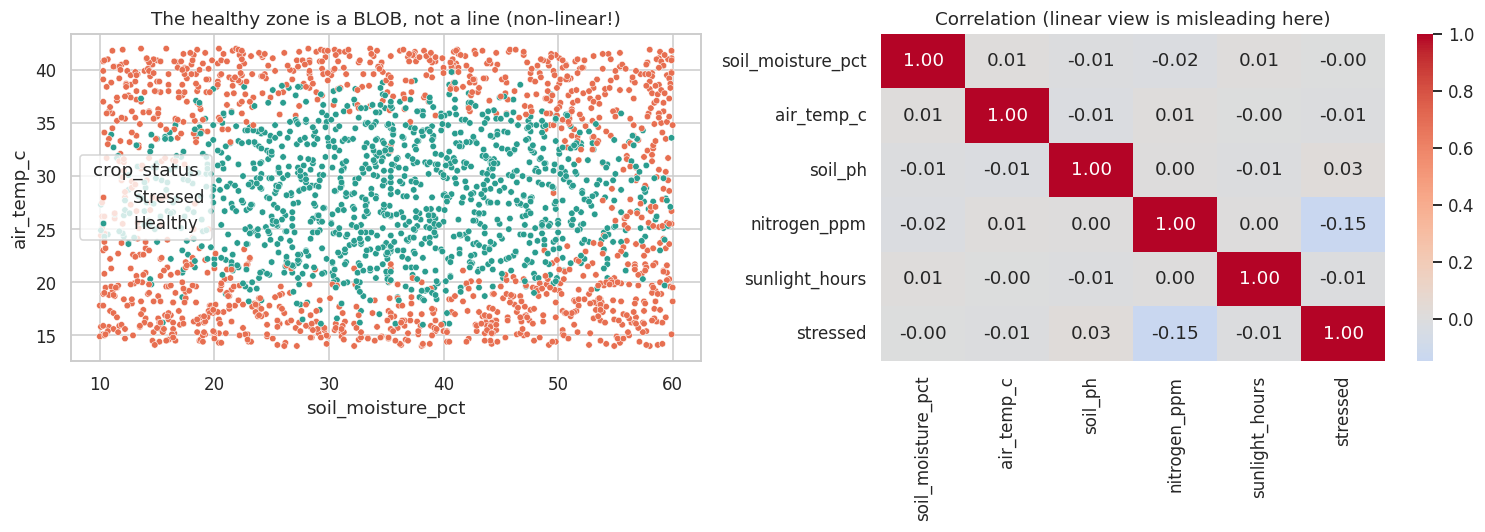

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=fm.sample(2500, random_state=1), x='soil_moisture_pct', y='air_temp_c', hue='crop_status', palette={'Healthy': '#2a9d8f', 'Stressed': '#e76f51'}, s=18, ax=ax[0])
ax[0].set_title('The healthy zone is a BLOB, not a line (non-linear!)')
sns.heatmap(fm.drop(columns='crop_status').corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[1]); ax[1].set_title('Correlation (linear view is misleading here)')
plt.tight_layout(); plt.show()

### 3.5 Kernel comparison — *see* the boundary
We use only 2 features (moisture, temperature) so we can draw the decision boundary. Scaling is done inside a **Pipeline** (so test data never leaks into the scaler).

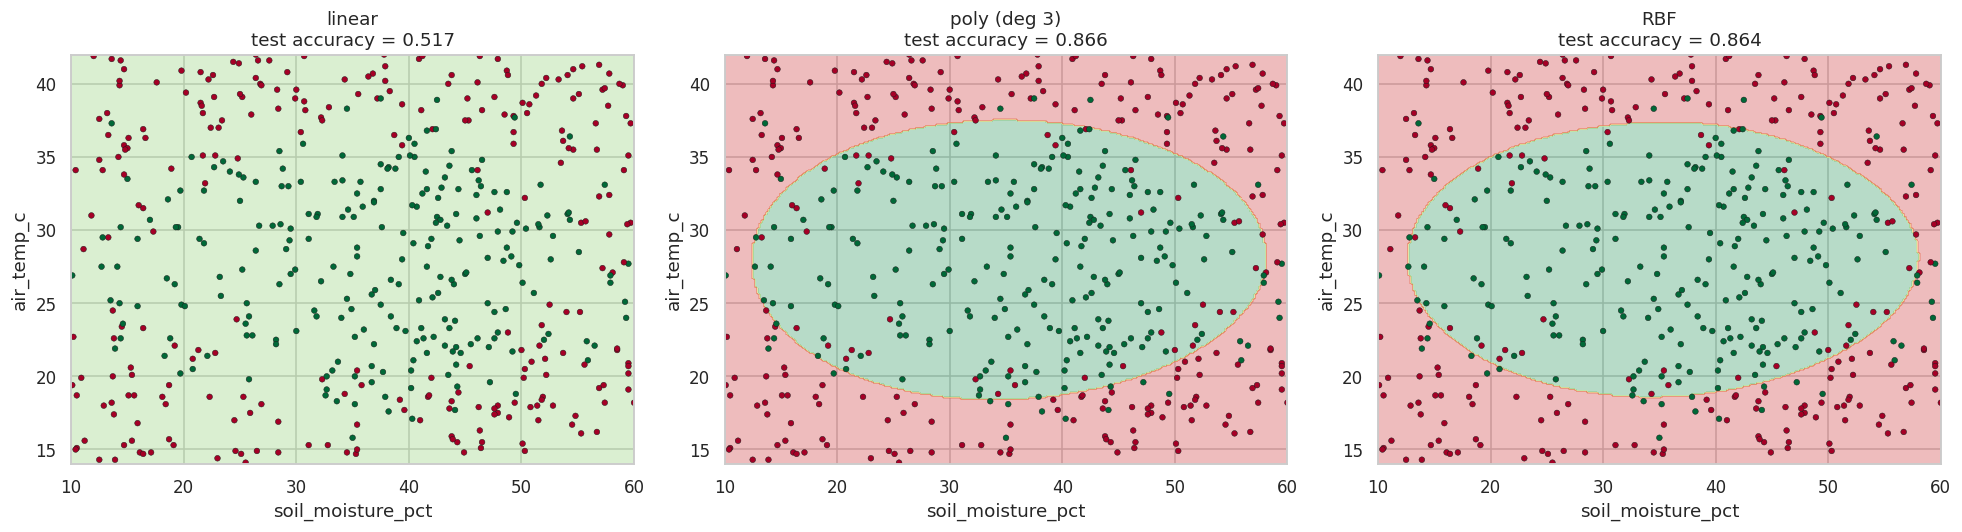

In [28]:
f2 = ['soil_moisture_pct', 'air_temp_c']
A_tr, A_te, ay_tr, ay_te = train_test_split(fm[f2], fm['stressed'], test_size=.25, stratify=fm['stressed'], random_state=0)
kernels = {'linear': dict(kernel='linear'), 'poly (deg 3)': dict(kernel='poly', degree=3, coef0=1), 'RBF': dict(kernel='rbf', gamma='scale')}
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
xs = np.linspace(A_tr.iloc[:, 0].min(), A_tr.iloc[:, 0].max(), 250); ys = np.linspace(A_tr.iloc[:, 1].min(), A_tr.iloc[:, 1].max(), 250)
gx, gy = np.meshgrid(xs, ys); grid = pd.DataFrame(np.c_[gx.ravel(), gy.ravel()], columns=f2)
kres = {}
for a, (nm, kw) in zip(ax, kernels.items()):
    pipe = Pipeline([('sc', StandardScaler()), ('svm', SVC(C=1, **kw))]).fit(A_tr, ay_tr)
    acc = pipe.score(A_te, ay_te); kres[nm] = acc
    a.contourf(gx, gy, pipe.predict(grid).reshape(gx.shape), alpha=.3, cmap='RdYlGn_r')
    s = A_te.sample(500, random_state=1); a.scatter(s.iloc[:, 0], s.iloc[:, 1], c=ay_te.loc[s.index], cmap='RdYlGn_r', s=14, edgecolor='k', linewidth=.3)
    a.set_title(f'{nm}\ntest accuracy = {acc:.3f}'); a.set_xlabel(f2[0]); a.set_ylabel(f2[1])
plt.tight_layout(); plt.show()

**Observation:** the *linear* road cuts the blob badly; *polynomial* bends but is rigid; **RBF wraps the healthy zone** almost perfectly.
Lesson: *match the kernel to the shape of your data*. When unsure → start with RBF.

### 3.6 Feeling `C` and `gamma` 🎛️
Rows: increasing **C** (stricter). Columns: increasing **gamma** (more local).

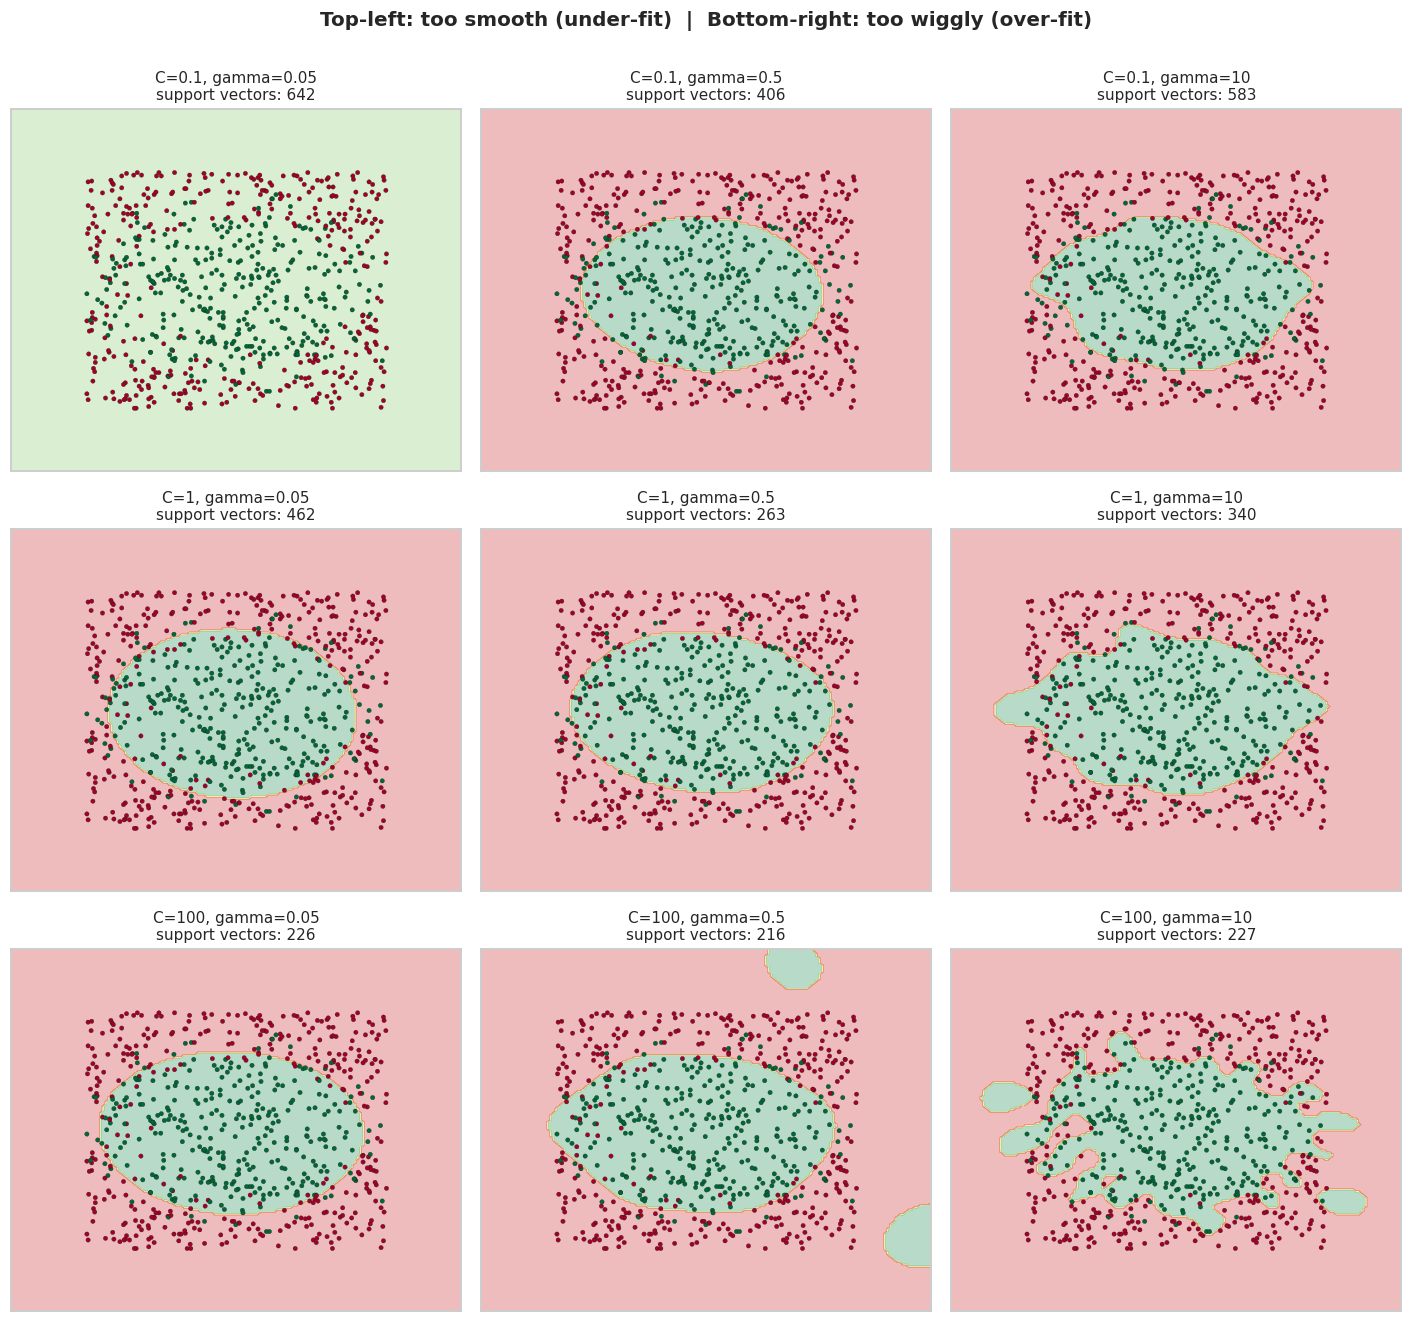

In [29]:
sub = pd.concat([A_tr, ay_tr], axis=1).sample(700, random_state=3)
sc = StandardScaler().fit(sub[f2]); Xs = sc.transform(sub[f2]); ys_ = sub['stressed'].values
gxs, gys = np.meshgrid(np.linspace(-2.6, 2.6, 160), np.linspace(-2.6, 2.6, 160))
fig, ax = plt.subplots(3, 3, figsize=(13, 12))
for i, Cv in enumerate([0.1, 1, 100]):
    for j, gv in enumerate([0.05, 0.5, 10]):
        m = SVC(kernel='rbf', C=Cv, gamma=gv).fit(Xs, ys_)
        ax[i, j].contourf(gxs, gys, m.predict(np.c_[gxs.ravel(), gys.ravel()]).reshape(gxs.shape), alpha=.3, cmap='RdYlGn_r')
        ax[i, j].scatter(Xs[:, 0], Xs[:, 1], c=ys_, cmap='RdYlGn_r', s=8, edgecolor='k', linewidth=.2)
        ax[i, j].set_title(f'C={Cv}, gamma={gv}\nsupport vectors: {len(m.support_)}', fontsize=10); ax[i, j].set_xticks([]); ax[i, j].set_yticks([])
plt.suptitle('Top-left: too smooth (under-fit)  |  Bottom-right: too wiggly (over-fit)', y=1.0, fontsize=13, weight='bold'); plt.tight_layout(); plt.show()

- **Small C + small gamma** → almost a flat blur (under-fit).
- **Large C + large gamma** → tiny islands around every point (over-fit, memorised!). Notice the **number of support vectors explodes**.
- The sweet spot is in the middle → found by **cross-validated grid search**.

### 3.7 Why scaling is mandatory for SVM (proof)

No scaling : 0.577
With scaling: 0.895


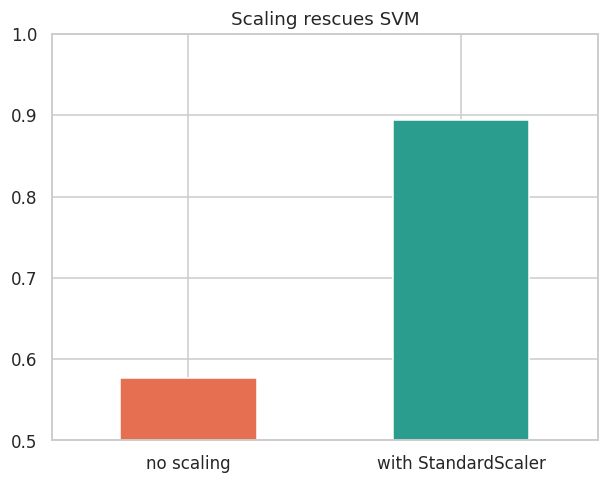

In [30]:
F = ['soil_moisture_pct', 'air_temp_c', 'soil_ph', 'nitrogen_ppm', 'sunlight_hours']
B_tr, B_te, by_tr, by_te = train_test_split(fm[F], fm['stressed'], test_size=.25, stratify=fm['stressed'], random_state=0)
raw = SVC(kernel='rbf').fit(B_tr, by_tr).score(B_te, by_te)
scaled = Pipeline([('sc', StandardScaler()), ('svm', SVC(kernel='rbf'))]).fit(B_tr, by_tr).score(B_te, by_te)
print(f'No scaling : {raw:.3f}\nWith scaling: {scaled:.3f}')
pd.Series({'no scaling': raw, 'with StandardScaler': scaled}).plot.bar(rot=0, color=['#e76f51', '#2a9d8f'], ylim=(0.5, 1), title='Scaling rescues SVM'); plt.show()

### 3.8 Full SVC pipeline with grid search

Search time: 9.1s
Best params: {'svm__C': 5, 'svm__gamma': 0.05} | CV F1: 0.908
              precision    recall  f1-score   support

     Healthy       0.89      0.90      0.89       724
    Stressed       0.90      0.89      0.90       776

    accuracy                           0.89      1500
   macro avg       0.89      0.89      0.89      1500
weighted avg       0.89      0.89      0.89      1500



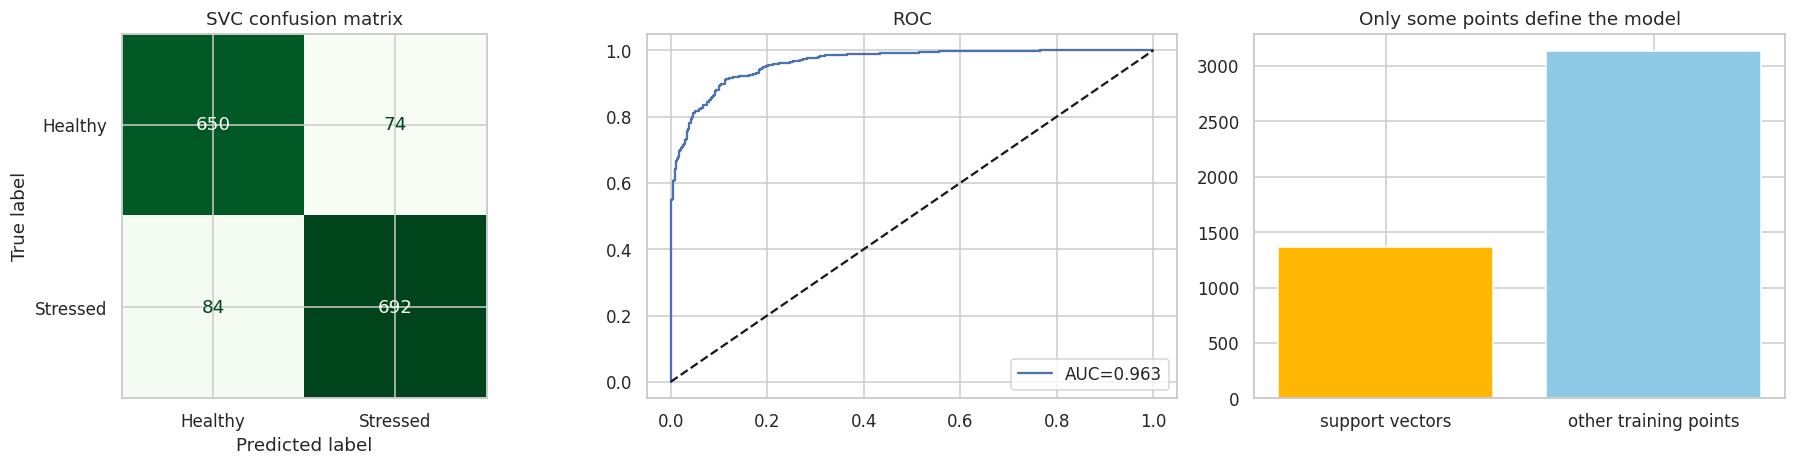

In [31]:
pipe = Pipeline([('sc', StandardScaler()), ('svm', SVC(kernel='rbf', probability=False))])
grid = GridSearchCV(pipe, {'svm__C': [0.5, 1, 5, 20], 'svm__gamma': ['scale', 0.05, 0.5, 2]}, cv=3, scoring='f1', n_jobs=-1)
t0 = time.time(); grid.fit(B_tr, by_tr); print('Search time: %.1fs' % (time.time() - t0))
print('Best params:', grid.best_params_, '| CV F1:', round(grid.best_score_, 3))
best = grid.best_estimator_; pred = best.predict(B_te)
print(classification_report(by_te, pred, target_names=['Healthy', 'Stressed']))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
ConfusionMatrixDisplay(confusion_matrix(by_te, pred), display_labels=['Healthy', 'Stressed']).plot(ax=ax[0], colorbar=False, cmap='Greens'); ax[0].set_title('SVC confusion matrix')
fpr, tpr, _ = roc_curve(by_te, best.decision_function(B_te)); ax[1].plot(fpr, tpr, label=f'AUC={roc_auc_score(by_te, best.decision_function(B_te)):.3f}'); ax[1].plot([0, 1], [0, 1], 'k--'); ax[1].legend(); ax[1].set_title('ROC')
sv = len(best.named_steps['svm'].support_); ax[2].bar(['support vectors', 'other training points'], [sv, len(B_tr) - sv], color=['#ffb703', '#8ecae6']); ax[2].set_title('Only some points define the model')
plt.tight_layout(); plt.show()

### 3.9 SVC vs boosting on the same farm data

,accuracy,f1,predict_sec
model,,,
"SVC (RBF, tuned)",0.895,0.898,0.063
XGBoost,0.892,0.895,0.143
LightGBM,0.886,0.889,0.159
CatBoost,0.893,0.896,0.388


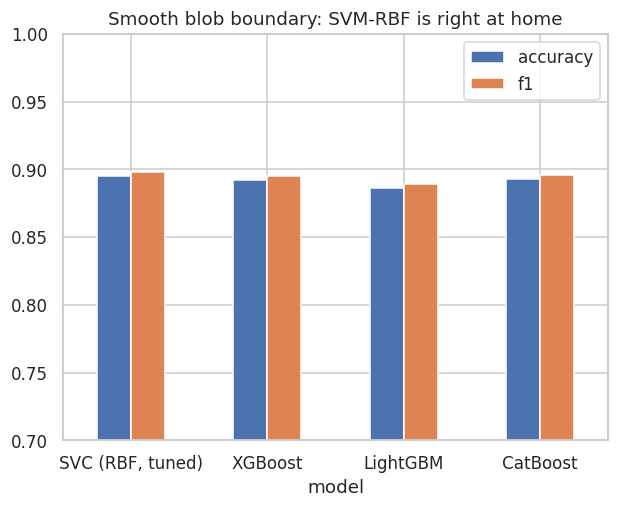

In [32]:
cmp = {'SVC (RBF, tuned)': best, 'XGBoost': xgb.XGBClassifier(n_estimators=300, learning_rate=.05, max_depth=4, random_state=0),
       'LightGBM': lgb.LGBMClassifier(n_estimators=300, learning_rate=.05, num_leaves=15, verbose=-1, random_state=0),
       'CatBoost': CatBoostClassifier(iterations=300, learning_rate=.05, depth=4, verbose=0, random_seed=0)}
out = []
for n_, m in cmp.items():
    t0 = time.time()
    if n_ != 'SVC (RBF, tuned)': m.fit(B_tr, by_tr)
    p = m.predict(B_te); out.append(dict(model=n_, accuracy=accuracy_score(by_te, p), f1=f1_score(by_te, p), predict_sec=time.time() - t0))
o = pd.DataFrame(out).set_index('model').round(3); display(o)
o[['accuracy', 'f1']].plot.bar(rot=0, ylim=(.7, 1), title='Smooth blob boundary: SVM-RBF is right at home'); plt.show()

# PART 4 — SVR: Support Vector *Regression* 📏

## 4.1 The idea — the tailor's tolerance tube 🧵
**Analogy:** a tailor stitches a line along your measurements. A tiny error (±1 cm) doesn't matter — *no one notices*. Only errors **beyond** 1 cm are penalised.
SVR draws a smooth curve with an **ε-tube** (epsilon tube) around it:
- Points **inside the tube** → zero penalty (not support vectors).
- Points **outside the tube** → penalised; they become the support vectors that shape the curve.
- `C` = how hard we punish points outside the tube. `epsilon` = tube half-width. `gamma` = curve flexibility (RBF).

**Why SVR?** Smooth, robust to small noise, works well on **small/medium** data with a curved relationship.
Its weakness: slow on large data (training grows roughly with n²).

## 4.2 Scenario 4 — 🔌 Demand vs temperature, as a smooth curve
First, the single-feature picture (temperature → demand, residential zone, 3 pm–11 pm only to keep it clean).

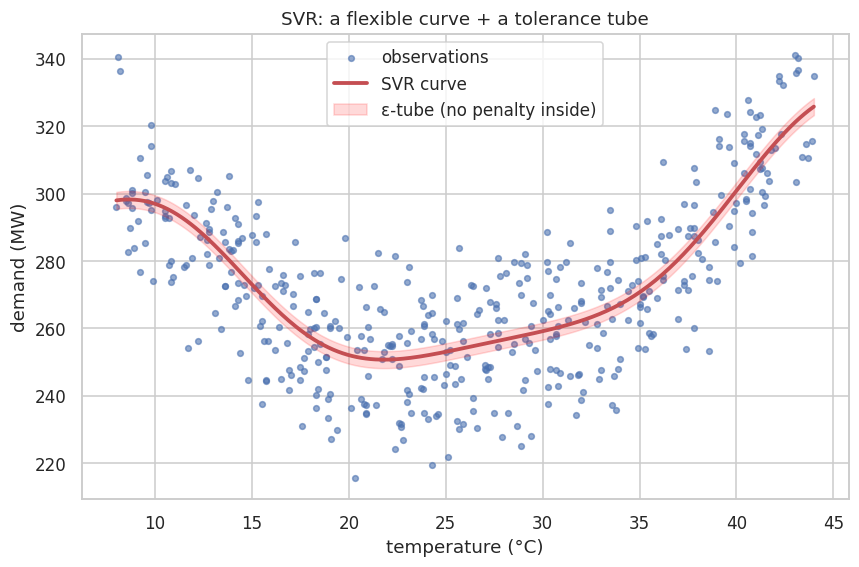

In [33]:
one = el[(el['zone'] == 'Residential') & (el['hour'].between(15, 23)) & (el['is_holiday'] == 0)].sample(450, random_state=0)
Xt, yt = one[['temperature_c']], one['demand_mw']
tmp = TransformedTargetRegressor(Pipeline([('sc', StandardScaler()), ('svr', SVR(kernel='rbf', C=10, epsilon=0.1))]), transformer=StandardScaler()).fit(Xt, yt)
tt = np.linspace(8, 44, 300).reshape(-1, 1); line = tmp.predict(pd.DataFrame(tt, columns=['temperature_c']))
eps_mw = 0.1 * yt.std()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(Xt, yt, s=14, alpha=.6, label='observations')
ax.plot(tt, line, 'r', lw=2.5, label='SVR curve'); ax.fill_between(tt.ravel(), line - eps_mw, line + eps_mw, color='red', alpha=.15, label='ε-tube (no penalty inside)')
ax.set_xlabel('temperature (°C)'); ax.set_ylabel('demand (MW)'); ax.legend(); ax.set_title('SVR: a flexible curve + a tolerance tube'); plt.show()

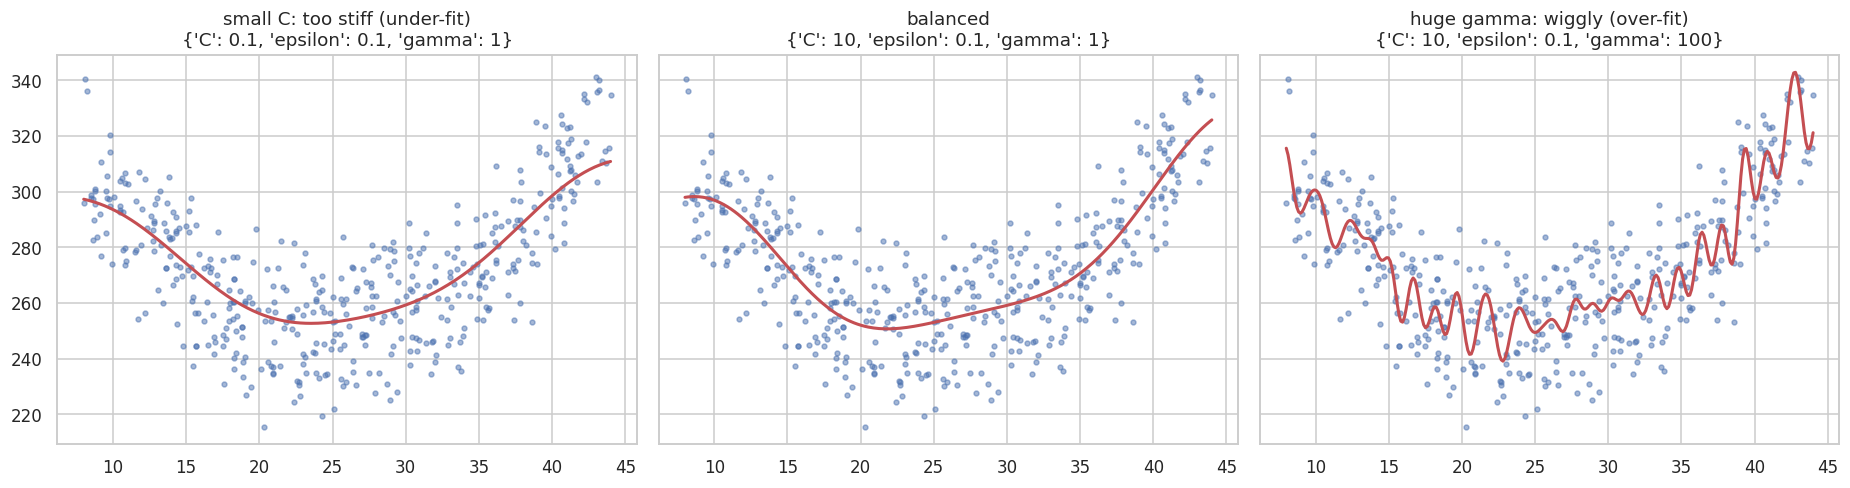

In [34]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
settings = [dict(C=0.1, epsilon=0.1, gamma=1), dict(C=10, epsilon=0.1, gamma=1), dict(C=10, epsilon=0.1, gamma=100)]
names = ['small C: too stiff (under-fit)', 'balanced', 'huge gamma: wiggly (over-fit)']
for a, st, nm in zip(ax, settings, names):
    r = TransformedTargetRegressor(Pipeline([('sc', StandardScaler()), ('svr', SVR(kernel='rbf', **st))]), transformer=StandardScaler()).fit(Xt, yt)
    a.scatter(Xt, yt, s=10, alpha=.5); a.plot(tt, r.predict(pd.DataFrame(tt, columns=['temperature_c'])), 'r', lw=2); a.set_title(f'{nm}\n{st}')
plt.tight_layout(); plt.show()

### 4.3 Kernel comparison for regression
A **linear** kernel can only draw a straight line through a U-shaped cloud — useless. RBF follows the U.

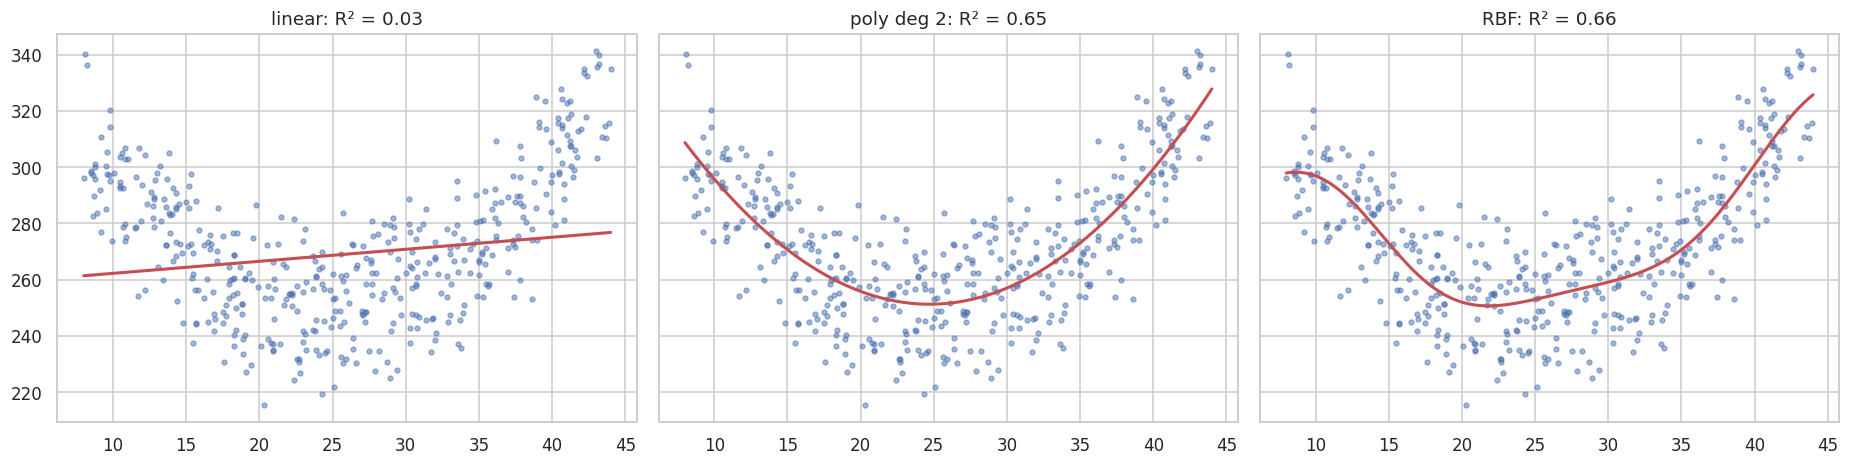

In [35]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4), sharey=True)
for a, (nm, kw) in zip(ax, {'linear': dict(kernel='linear', C=10), 'poly deg 2': dict(kernel='poly', degree=2, C=10, coef0=1), 'RBF': dict(kernel='rbf', C=10)}.items()):
    r = TransformedTargetRegressor(Pipeline([('sc', StandardScaler()), ('svr', SVR(**kw))]), transformer=StandardScaler()).fit(Xt, yt)
    a.scatter(Xt, yt, s=10, alpha=.5); a.plot(tt, r.predict(pd.DataFrame(tt, columns=['temperature_c'])), 'r', lw=2)
    a.set_title(f'{nm}: R² = {r2_score(yt, r.predict(Xt)):.2f}')
plt.tight_layout(); plt.show()

### 4.4 Full SVR on all features + head-to-head with LightGBM
SVR needs: **scaled numbers**, **one-hot encoded categories**, **no missing values** (we fill humidity with the median) and a **scaled target**.

In [36]:
num = ['temperature_c', 'humidity_pct', 'hour', 'day_of_week', 'is_holiday', 'industrial_index']
from sklearn.impute import SimpleImputer
pre = ColumnTransformer([('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num),
                         ('cat', OneHotEncoder(handle_unknown='ignore'), ['zone'])])
svr = TransformedTargetRegressor(Pipeline([('pre', pre), ('svr', SVR(kernel='rbf', C=20, epsilon=0.05, gamma='scale'))]), transformer=StandardScaler())
t0 = time.time(); svr.fit(Xr_tr, yr_tr); t_svr = time.time() - t0
p_svr = svr.predict(Xr_te)
lgbm = reg['LightGBM']; p_lgb = rpred['LightGBM']
final = pd.DataFrame({'SVR (RBF)': dict(RMSE=mean_squared_error(yr_te, p_svr) ** .5, MAE=mean_absolute_error(yr_te, p_svr), R2=r2_score(yr_te, p_svr), train_sec=t_svr),
                      'LightGBM': rres.loc['LightGBM'].to_dict()}).T.round(3)
final

,RMSE,MAE,R2,train_sec
SVR (RBF),8.289,6.445,0.983,10.658
LightGBM,6.929,5.509,0.988,0.337


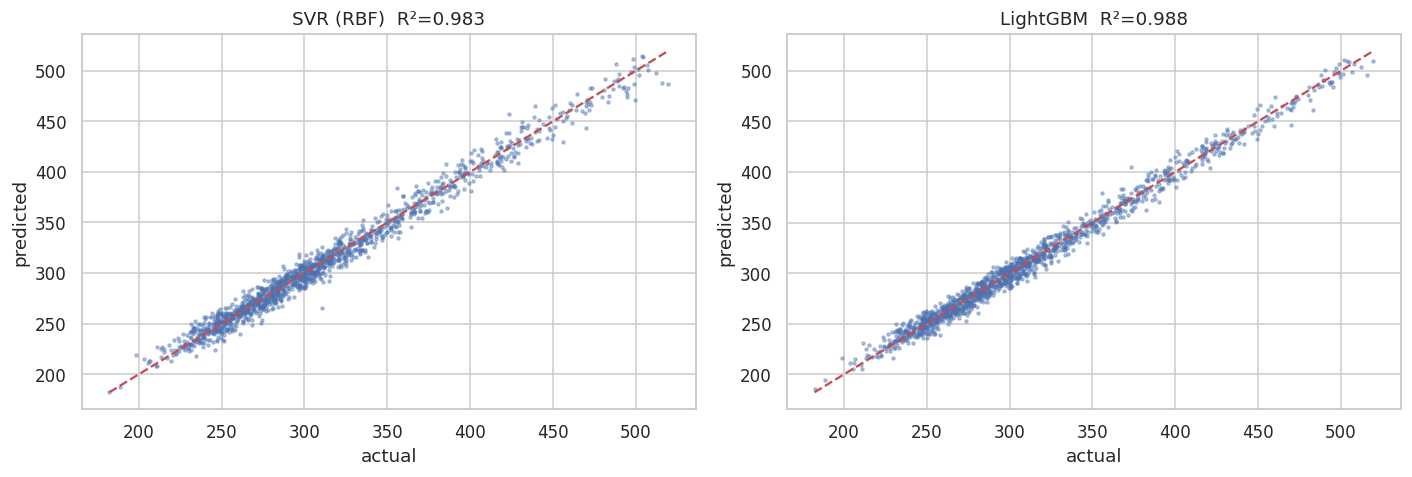

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, (nm, p) in zip(ax, {'SVR (RBF)': p_svr, 'LightGBM': p_lgb}.items()):
    a.scatter(yr_te, p, s=4, alpha=.4); lim = [yr_te.min(), yr_te.max()]; a.plot(lim, lim, 'r--'); a.set_title(f'{nm}  R²={r2_score(yr_te, p):.3f}'); a.set_xlabel('actual'); a.set_ylabel('predicted')
plt.tight_layout(); plt.show()

# PART 5 — Wrap-up

## 5.1 Which model when? (the one-page decision guide)

| Question | Answer |
|---|---|
| Tabular data, mixed types, missing values, want top accuracy | **Boosting** (XGBoost / LightGBM / CatBoost) |
| Millions of rows | **LightGBM** (SVM becomes too slow) |
| Many categorical columns | **CatBoost** |
| Small/medium data, smooth curved boundary, numeric features | **SVM (RBF)** |
| High-dimensional sparse data (text) | **Linear SVM** |
| Need to explain which features matter | Boosting feature importance (SVM-RBF is a black box) |
| Features not scaled & you don't want to scale | Boosting (trees ignore scale); SVM **requires** scaling |

## 5.2 Cheat-sheet notes 📝

**Boosting II**
- Boosting = sequential weak trees, each fixes previous errors. `prediction = Σ η·tree`.
- **XGBoost** = regularised, level-wise, reliable. **LightGBM** = leaf-wise, histogram, fastest. **CatBoost** = native categoricals, symmetric trees, strong defaults.
- Tune: `learning_rate ↓ + n_estimators ↑ + early_stopping`; control complexity with depth/leaves; fight over-fit with subsample, colsample, regularisation.
- Imbalanced data → `scale_pos_weight` / class weights and judge by **AUC / F1 / PR-AUC**, not accuracy.
- Always check for **leakage** — if the score is too good, be suspicious.

**SVM**
- Maximise the margin; **support vectors** define the model.
- `C`: strictness (↑ = narrow margin, over-fit risk). `gamma`: reach of each point (↑ = wiggly). `epsilon` (SVR): tolerance tube.
- Kernel trick: separate non-linear data by implicitly lifting to higher dimensions. Linear → RBF → poly.
- **Scale your features. Always.** Use `Pipeline` + `GridSearchCV`.
- Complexity ~ O(n²–n³): good up to ~tens of thousands of rows.

## 5.3 💪 Practice (your turn!)
1. **Beat your Day-13 score:** tune the best booster on `loan_default.csv` (try `GridSearchCV`/Optuna). Report ROC-AUC *and* F1. 
   *Hint:* lower `learning_rate` + early stopping on a **validation** split (not the test set!).
2. Replace the 0.5 threshold with the best-F1 threshold using `precision_recall_curve`. Does recall on defaulters improve?
3. Add a new feature `loan_to_income = loan_amount / (monthly_income*12)` and check if importance rises.
4. Try SVC kernels `poly` with degrees 2, 3, 4 on the farm data — which wins and why?
5. Use `SVC(probability=True)` and compare calibration (`calibration_curve`) with CatBoost.
6. **Challenge:** make SVR faster using only 2,000 training rows — how much R² do you lose?
7. **Debug challenge:** deliberately keep `recovery_agent_assigned` in the loan data. What AUC do you get, and why is it a lie?

🎉 You now know *what* each model does, *why* it is used, and *when* to pick it.